<a href="https://colab.research.google.com/github/Pascingo/CTA-media-analysis/blob/Ga%C3%ABl/Stage_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 2: Embedding Models Training and Analysis (Track 1: AI Governance)

In this notebook we train and compare embedding models on the AI Media Dataset. The selected track (AI Governance) is used as the focus case for the analysis. This first part prepares the data and trains a classical Word2Vec model:

1. Setup and download of the dataset
2. Loading and cleaning the data (time frame, text cleaning, duplicates, language filter)
3. Train / validation / test split (shared by the whole team)
4. Sentences and tokens
5. Detection of multi-word terms (phrases)
6. Training of Word2Vec
7. Nearest neighbours of AI Governance terms
8. Document vectors and separation of governance articles

All results that take long to compute (cleaned data, split, phrase model, Word2Vec model) are stored in the team's Google Drive, so the slow steps only have to run once.

## 1. Setup (Contributor: TBD)

We put all imports and settings at the top. The time frame and the folder structure are the same as in Stage 1.

**Cache:** With `USE_CACHE = True`, results that already exist in the Drive folder `CTA-media-analysis/stage2` are loaded instead of computed again. Set it to `False` to recompute everything (e.g. after changing the cleaning). The Drive folder must be available in "My Drive" (for a shared folder: add a shortcut to "My Drive").

In [16]:
!pip install -q gensim ftfy

import ast
import glob
import html
import os
import re
import shutil
import unicodedata
from collections import Counter

import gdown
import nltk
import numpy as np
import pandas as pd
import plotly.express as px
from ftfy import fix_text
from gensim.models import Word2Vec
from gensim.models.phrases import FrozenPhrases, Phrases
from google.colab import drive
from nltk.corpus import stopwords
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_val_score, train_test_split
from tqdm.auto import tqdm

tqdm.pandas()

# Settings (same time frame as in Stage 1)
TEXT_COLUMN = "content"
START_DATE = "2024-09-01"
END_DATE = "2026-08-31"
RANDOM_STATE = 42

# Load existing results from the cache instead of computing them again
USE_CACHE = True

# Local folder (same as in Stage 1)
DATA_FOLDER = "data"
os.makedirs(DATA_FOLDER, exist_ok=True)

# Fixed dataset version from Stage 1 (Google Drive file ID of ai_media_dataset_20260911.csv)
DATASET_DRIVE_ID = "1CVjm5_r8EmMPjaN9qghdUYoFGlRy7Sz6"
DATASET_FILE = os.path.join(DATA_FOLDER, "ai_media_dataset_20260911.csv")

# Stage 2 results, stored locally and in the team's Google Drive
STAGE2_DRIVE_FOLDER = "/content/drive/MyDrive/CTA-media-analysis/stage2"
CLEANED_FILE = os.path.join(DATA_FOLDER, "stage2_cleaned.parquet")
SPLITS_FILE = os.path.join(DATA_FOLDER, "splits.csv")
BIGRAM_FILE = os.path.join(DATA_FOLDER, "bigram.phraser")
W2V_FILE = os.path.join(DATA_FOLDER, "w2v_train.model")

drive.mount("/content/drive")
os.makedirs(STAGE2_DRIVE_FOLDER, exist_ok=True)


def save_to_drive(path):
    """Copy a result to the Drive folder. gensim stores large models in several files (model + .npy), so we copy all of them."""
    for file in glob.glob(path + "*"):
        shutil.copy(file, STAGE2_DRIVE_FOLDER)


def restore_from_drive(path):
    """Copy a result from the Drive folder to DATA_FOLDER if it is not there yet. Returns True if the file exists."""
    if not os.path.exists(path):
        pattern = os.path.join(STAGE2_DRIVE_FOLDER, os.path.basename(path)) + "*"
        for file in glob.glob(pattern):
            shutil.copy(file, DATA_FOLDER)
    return os.path.exists(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Download of the dataset

We use the same fixed dataset version as in Stage 1 (2026-09-11). Only this file is downloaded from the public Google Drive folder, and only if it is not already in the folder `data`.

In [17]:
if not os.path.exists(DATASET_FILE):
    gdown.download(id=DATASET_DRIVE_ID, output=DATASET_FILE, quiet=False)

if not os.path.exists(DATASET_FILE):
    raise FileNotFoundError(f"{DATASET_FILE} not found. Please check the Google Drive folder.")

print("Using file:", DATASET_FILE)

Using file: data/ai_media_dataset_20260911.csv


## 2. Loading and cleaning the data (Contributor: TBD)

In Stage 1 we cleaned the text for lemma-based methods (everything in lowercase, lemmatized). For Stage 2 we need two other versions of the text:

- **`base_text`** for the language models in the fine-tuning part: upper and lower case, punctuation and sentence structure stay, because LLMs are trained on normal text.
- **`w2v_text`** for Word2Vec: lowercase and only letters, digits and sentence punctuation, so that the same word always gets the same token.

The cleaning takes several minutes (mainly the repair of encoding errors) and is therefore cached. It has the following steps:

1. **Paragraphs:** The column `content` stores a Python list of paragraphs as a string (`"['Paragraph 1', 'Paragraph 2']"`). We convert it back to a list and join the paragraphs, otherwise the brackets and quotes would stay in the text.
2. **Encoding errors:** Some articles contain broken characters, e.g. `Weâ€™ve` instead of `We've` (we saw this in the NER results of Stage 1). `ftfy` repairs them before we remove the remaining special characters. A few product pages contain `â€�`, a quotation mark that cannot be repaired automatically; we replace it with `"`.
3. **Basic cleaning:** HTML tags and entities, URLs, typographic dashes and quotes. Some sources write `year' s` instead of `year's`; we join these again.
4. **Time frame:** Like in Stage 1 we only keep September 2024 to August 2026.
5. **Duplicates:** We remove duplicates after the cleaning, because two texts can only differ in HTML or encoding. We also remove duplicate URLs, so that the URL can be used as a unique ID of an article.
6. **Language:** The dataset also contains about 350 non-English articles, mainly German, Spanish, Portuguese and French (in a first run, the nearest neighbours of `open_source` were German words like `webanalyselosung_die`). For every article we compute the share of stop words of several languages among the first 300 words. An article is kept if at least 10% of these words are English stop words **and** the English share is higher than the share of every other language. A fixed threshold alone is not enough: English product pages with many lists and technical terms have only 15-20% English stop words, while Spanish or Portuguese pages with English navigation text reach up to 15%. Texts in non-Latin scripts (e.g. Japanese, Korean) are almost empty after the ASCII conversion and are removed by the 10% threshold. The language check is fast and therefore not part of the cache, so the threshold can be changed without running the cleaning again.
7. **Word2Vec text:** lowercase, possessive `'s` removed, hyphens between words replaced by a space ("london-based" -> "london based"), but kept between a name and a number ("gpt-4o" -> "gpt_4o"). The governance acronyms and names of laws are replaced with the same fixed tokens as in Stage 1 (e.g. "eu ai act" -> `eu_ai_act`). Many articles write the full name followed by the abbreviation, e.g. "General Data Protection Regulation (GDPR)". After the replacement this becomes "gdpr (gdpr)", so directly repeated words are reduced to one (otherwise `Phrases` would learn the token `gdpr_gdpr`).

In [18]:
MIN_ENGLISH_SHARE = 0.1
nltk.download("stopwords", quiet=True)
EN_STOP = set(stopwords.words("english"))

# Languages that occur in the dataset (and related ones), to compare their stop word shares with English
OTHER_LANGUAGES = ["german", "french", "spanish", "portuguese", "italian", "dutch", "indonesian",
                   "romanian", "swedish", "danish", "norwegian", "finnish", "turkish", "hungarian"]
OTHER_STOP = {lang: set(stopwords.words(lang)) for lang in OTHER_LANGUAGES}

# Same governance terms as in Stage 1 ("eu ai act" has to be replaced before "ai act")
ACRONYM_MAP = {
    r"\beu ai act\b": "eu_ai_act",
    r"\bai act\b": "ai_act",
    r"\bgeneral data protection regulation\b": "gdpr",
    r"\bfederal trade commission\b": "ftc",
    r"\blarge language models?\b": "llm",
    r"\bnational institute of standards and technology\b": "nist",
    r"\bgeneral purpose ai\b": "gpai",
    r"\bu\.s\.(?=\W|$)|\bunited states\b": "usa",
    r"\beuropean union\b": "eu",
    r"\bartificial intelligence\b": "ai",
}
ACRONYM_PATTERNS = [(re.compile(p), token) for p, token in ACRONYM_MAP.items()]


def parse_paragraphs(raw):
    """Turn the string "['Paragraph 1', 'Paragraph 2']" into one text."""
    if not isinstance(raw, str):
        return ""
    try:
        paragraphs = ast.literal_eval(raw)
        if isinstance(paragraphs, list):
            return " ".join(str(p) for p in paragraphs)
    except (ValueError, SyntaxError):
        pass
    return raw.strip("[]")


def base_clean(text):
    """Cleaning for all models: keeps upper and lower case and punctuation."""
    text = fix_text(text)                                        # "Weâ€™ve" -> "We've"
    text = text.replace("\u00e2\u20ac\ufffd", '"')                     # "â€�" (quote that ftfy cannot repair)
    text = html.unescape(text)                                   # "&amp;" -> "&"
    text = re.sub(r"<[^>]+>", " ", text)                         # HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)          # URLs
    text = re.sub(r"[\u2010-\u2015]", "-", text)                 # all dash variants -> "-"
    text = re.sub(r"[\u2018\u2019]", "'", text)                  # typographic apostrophes -> '
    text = re.sub(r"[\u201c\u201d]", '"', text)                  # typographic quotes -> "
    text = re.sub(r"(\w)\s*'\s+(s|t|re|ve|ll|d|m)\b", r"\1'\2", text)  # "year' s" -> "year's"
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", text).strip()


def w2v_clean(text):
    """Additional cleaning for Word2Vec."""
    text = text.lower()
    text = re.sub(r"'s\b", "", text)                                           # openai's -> openai
    text = re.sub(r"(?<=[a-z])-(?=[a-z])", " ", text)                          # london-based -> london based
    text = re.sub(r"(?<=[a-z0-9])-(?=[0-9])|(?<=[0-9])-(?=[a-z])", "_", text)  # gpt-4o -> gpt_4o
    text = text.replace("/", " ")
    for pattern, token in ACRONYM_PATTERNS:                                    # eu ai act -> eu_ai_act
        text = pattern.sub(token, text)
    text = re.sub(r"\b(\w+)(?:\W+\1\b)+", r"\1", text)                     # "gdpr ( gdpr)" -> "gdpr"
    text = re.sub(r"[^a-z0-9_\s.,!?]", " ", text)                               # other symbols
    return re.sub(r"\s+", " ", text).strip()


def language_shares(text, n_words=300):
    """Share of English stop words and the highest share of another language among the first n_words words."""
    words = re.findall(r"[a-z]+", text[:5000].lower())[:n_words]
    if not words:
        return 0.0, 0.0
    english = sum(word in EN_STOP for word in words) / len(words)
    other = max(sum(word in stop for word in words) for stop in OTHER_STOP.values()) / len(words)
    return english, other


def is_english_text(text):
    english, other = language_shares(text)
    return english >= MIN_ENGLISH_SHARE and english >= other


# Small checks of the cleaning functions
assert parse_paragraphs("['First part.', 'Second part.']") == "First part. Second part."
assert base_clean("We\u2019ve seen the <b>EU</b> year\u2019 s plan") == "We've seen the EU year's plan"
assert w2v_clean("The EU AI Act and OpenAI's GPT-4o, a London-based U.S. firm") == "the eu_ai_act and openai gpt_4o, a london based usa firm"
assert w2v_clean("The General Data Protection Regulation (GDPR) applies") == "the gdpr applies"
assert is_english_text("This is a text about the rules for AI in the EU")
assert not is_english_text("Die Webanalyseloesung ist datenschutzfreundlich und wird von vielen Firmen in der EU genutzt")
assert not is_english_text("La computacion en la nube es uno de los avances mas importantes de la economia europea")
print("Cleaning tests passed.")

Cleaning tests passed.


In [19]:
if USE_CACHE and restore_from_drive(CLEANED_FILE):
    df_all = pd.read_parquet(CLEANED_FILE)
    print(f"Loaded cleaned data from cache: {df_all.shape}")
else:
    df_all = pd.read_csv(DATASET_FILE, usecols=["title", "date", "content", "domain", "url", "tags"])
    print(f"Original dataset: {df_all.shape}")

    # Time frame
    df_all["date"] = pd.to_datetime(df_all["date"], errors="coerce")
    df_all = df_all[(df_all["date"] >= START_DATE) & (df_all["date"] <= END_DATE)].copy()
    print(f"After date filter ({START_DATE} to {END_DATE}): {df_all.shape}")

    # Paragraphs and basic cleaning
    df_all["base_text"] = df_all[TEXT_COLUMN].progress_apply(lambda raw: base_clean(parse_paragraphs(raw)))
    df_all = df_all[df_all["base_text"].str.len() > 0]

    # Duplicates (after cleaning) and duplicate URLs
    df_all = df_all.drop_duplicates(subset=["base_text"]).drop_duplicates(subset=["url"])
    print(f"After removing empty texts and duplicates: {df_all.shape}")

    # Word2Vec text (computed for all articles, the language filter follows below)
    df_all["w2v_text"] = df_all["base_text"].progress_apply(w2v_clean)

    df_all.to_parquet(CLEANED_FILE)
    save_to_drive(CLEANED_FILE)
    print(f"Saved '{CLEANED_FILE}' (also in Google Drive).")

# Language filter (not cached, takes about one minute)
shares = df_all["base_text"].progress_apply(language_shares)
df_all["english_share"] = [english for english, _ in shares]
df_all["other_share"] = [other for _, other in shares]
is_english = (df_all["english_share"] >= MIN_ENGLISH_SHARE) & (df_all["english_share"] >= df_all["other_share"])

removed = df_all.loc[~is_english, ["title", "domain", "english_share", "other_share"]]
print(f"\nNon-English articles removed: {len(removed)} ({len(removed) / len(df_all):.1%})")
print("Most frequent domains of the removed articles:")
display(removed["domain"].value_counts().head(10))
print("Removed articles with the highest English share (closest to the decision):")
display(removed.sort_values("english_share", ascending=False).head(10))

df = df_all[is_english].copy()
assert df["url"].is_unique, "URLs must be unique, they are used as article ID."
print(f"Final corpus: {df.shape}")
df[["title", "base_text", "w2v_text"]].head(3)

Loaded cleaned data from cache: (47437, 8)


  0%|          | 0/47437 [00:00<?, ?it/s]


Non-English articles removed: 354 (0.7%)
Most frequent domains of the removed articles:


,count
domain,
blog.google,138
gitnation,56
t3,39
workday,19
alexanderthamm,19
emarsys,8
meer,8
press.bmwgroup,7
rolandberger,6


Removed articles with the highest English share (closest to the decision):


,title,domain,english_share,other_share
5117,Random Endless \n Output in Gemini API 1.5 Pro...,ai.google,0.220000,0.440000
39969,구글 I/O 2026: 에이전틱 제미나이 시대의 시작,blog.google,0.202128,0.297872
36706,How Forterra Made HR Operations Seamless,rippling,0.200000,0.210000
29564,From coding to orchestrating,wearedevelopers,0.163333,0.273333
39953,Conheça o Gemini Omni,blog.google,0.150000,0.360000
42261,FP & A con Workday,workday,0.143333,0.420000
16331,IA na Busca: da informação à inteligência,blog.google,0.140000,0.450000
42259,Planificación y análisis financieros ( FP & A),workday,0.140000,0.413333
23394,O compromisso do Google Cloud com uma nova era...,blog.google,0.133333,0.486667
26942,Lecciones de la Construcción de un Servidor MC...,gitnation,0.133333,0.393333


Final corpus: (47083, 10)


,title,base_text,w2v_text
0,Top 10 AI Companies in UK & Europe,With the field of AI accelerating all the time...,with the field of ai accelerating all the time...
1,“ Winner ” Takes Political Comedy Seriously,"This was in 2017, and she believed that the pu...","this was in 2017, and she believed that the pu..."
2,Optimizing Sustainable Construction with Smart...,A new study is shedding light on the latest in...,a new study is shedding light on the latest in...


The second table shows the removed articles with the highest share of English stop words, i.e. the cases closest to the decision. In our run these were mainly pages with an English beginning and a longer text in another language. If clearly English articles appear here, the rule should be adjusted.

## 3. Train / validation / test split (Contributor: TBD)

We split the articles into 80% training, 10% validation and 10% test data. The split is stratified by month, so every month has the same share in all three parts. This is important because the topics change over time (Stage 1): without stratification, for example, the test data could contain more articles about AI agents than the training data.

The split is done on the level of whole articles, so sentences of one article can never be in training and test data at the same time.

**The whole team uses the same split:** it is saved with the URL as a stable article ID in `splits.csv` in the Drive folder. If the file exists, it is loaded instead of creating a new split. The DataFrame index is not used as ID, because it changes as soon as the cleaning changes. If the cleaning is changed, `splits.csv` has to be deleted and created again, and all models have to be trained again on the new split.

In [20]:
df["month"] = df["date"].dt.to_period("M").astype(str)

if USE_CACHE and restore_from_drive(SPLITS_FILE):
    splits = pd.read_csv(SPLITS_FILE)
    df["split"] = df["url"].map(splits.set_index("url")["split"])
    missing = df["split"].isna().sum()
    if missing:
        raise ValueError(
            f"{missing} articles are not in {SPLITS_FILE}. The cleaning has changed: "
            "delete splits.csv (locally and in Drive) and create the split again."
        )
    print(f"Loaded split from '{SPLITS_FILE}'.")
else:
    train_ids, temp_ids = train_test_split(
        df.index, test_size=0.2, stratify=df["month"], random_state=RANDOM_STATE
    )
    val_ids, test_ids = train_test_split(
        temp_ids, test_size=0.5, stratify=df.loc[temp_ids, "month"], random_state=RANDOM_STATE
    )
    df["split"] = "train"
    df.loc[val_ids, "split"] = "val"
    df.loc[test_ids, "split"] = "test"

    df[["url", "date", "split"]].to_csv(SPLITS_FILE, index=False)
    save_to_drive(SPLITS_FILE)
    print(f"Created new split and saved it in '{SPLITS_FILE}' (also in Google Drive).")

print(df["split"].value_counts())

# Check: share of each month in the three parts (should be almost equal)
month_shares = pd.crosstab(df["month"], df["split"], normalize="columns").round(3)
display(month_shares.head(6))

Loaded split from 'data/splits.csv'.
split
train    37666
test      4709
val       4708
Name: count, dtype: int64


split,test,train,val
month,,,
2024-09,0.020,0.021,0.021
2024-10,0.045,0.045,0.045
2024-11,0.037,0.037,0.037
2024-12,0.030,0.031,0.031
2025-01,0.052,0.052,0.052
2025-02,0.038,0.038,0.038


## 4. Sentences and tokens (Contributor: TBD)

Word2Vec learns from sentences, so we split every article into sentences (a sentence ends with `.`, `!` or `?` followed by a space, so "3.1" stays one token). In every sentence we keep:

- tokens with at least two characters and at least one letter. Pure numbers and number ranges like `0.001_0.003` carry no meaning for the embeddings, while names like `gpt_4o` stay.
- no stop words. We use the NLTK stop word list, because it only contains function words. The lists of gensim and scikit-learn also contain content words like "computer" or "system", which are important in texts about AI.

Sentences with less than three tokens are removed.

In [39]:
SENTENCE_SPLIT = re.compile(r"(?<=[.!?])\s+")
TOKEN_PATTERN = re.compile(r"[a-z0-9_.]+")
HAS_LETTER = re.compile(r"[a-z]")


def to_sentences(text):
    sentences = []
    for sentence in SENTENCE_SPLIT.split(text):
        tokens = [t.strip(".") for t in TOKEN_PATTERN.findall(sentence)]
        tokens = [t for t in tokens if len(t) > 1 and t not in EN_STOP and HAS_LETTER.search(t)]
        if len(tokens) >= 3:
            sentences.append(tokens)
    return sentences


# Check: numbers and number ranges are removed, sentences with less than 3 tokens are dropped
assert to_sentences("the eu_ai_act from 2024 applies to gpt_4o. values 0.001_0.003 are removed here.") == [
    ["eu_ai_act", "applies", "gpt_4o"]
]

df["sentences"] = df["w2v_text"].progress_apply(to_sentences)
train_sents = [s for doc in df.loc[df["split"] == "train", "sentences"] for s in doc]

n_tokens = sum(len(s) for s in train_sents)
print(f"{len(train_sents):,} sentences, {n_tokens:,} tokens in the training split")

  0%|          | 0/47083 [00:00<?, ?it/s]

3,038,415 sentences, 37,252,088 tokens in the training split


## 5. Multi-word terms (Contributor: TBD)

Many important terms consist of several words, e.g. "machine learning" or "national security". gensim `Phrases` finds word pairs that occur together much more often than by chance and joins them into one token (`machine_learning`). Two passes would also find terms with three words; one pass is enough for our purpose.

The phrase model is learned **only on the training split**, so no information from the validation and test data is used. Later, the same model is applied to the validation and test data.

In [22]:
if USE_CACHE and restore_from_drive(BIGRAM_FILE):
    bigram = FrozenPhrases.load(BIGRAM_FILE)
    print("Loaded phrase model from cache.")
else:
    bigram = Phrases(train_sents, min_count=10, threshold=10).freeze()
    bigram.save(BIGRAM_FILE)
    save_to_drive(BIGRAM_FILE)

train_phr = [bigram[s] for s in tqdm(train_sents)]

phrase_counts = Counter(t for s in train_phr for t in s if "_" in t)
print(f"{len(phrase_counts):,} different multi-word tokens")

# Check: the most frequent phrases related to AI Governance
governance_stems = ["regulat", "govern", "_act", "law", "bias", "privacy", "safety", "ethic", "complian"]
governance_phrases = [(p, n) for p, n in phrase_counts.most_common() if any(stem in p for stem in governance_stems)]
print(governance_phrases[:50])

Loaded phrase model from cache.


  0%|          | 0/3038415 [00:00<?, ?it/s]

68,713 different multi-word tokens
[('privacy_policy', 4690), ('law_enforcement', 1604), ('regulatory_compliance', 1447), ('usa_government', 1299), ('security_compliance', 1151), ('federal_government', 1133), ('regulatory_requirements', 962), ('agree_privacy', 915), ('eu_ai_act', 860), ('old_actor', 825), ('take_action', 765), ('government_agencies', 723), ('compliance_risks', 712), ('unbiased_coverage', 653), ('ai_act', 617), ('ensure_compliance', 579), ('safety_efficiency', 578), ('regulatory_frameworks', 563), ('best_actions', 554), ('compliance_requirements', 552), ('insights_regulatory', 523), ('privacy_principles', 491), ('government_decision', 488), ('threat_actors', 488), ('ensuring_safety', 483), ('professional_acting', 482), ('governance_frameworks', 480), ('concerns_safety', 476), ('evolving_regulations', 474), ('privacy_concerns', 474), ('voice_actor', 467), ('police_government', 464), ('read_privacy', 460), ('bad_actors', 456), ('safety_pollution', 451), ('milk_safety', 44

## 6. Word2Vec (Contributor: TBD)

We train a skip-gram model (`sg=1`), because it learns better vectors for rare words than CBOW, and many governance terms are rare compared to general AI vocabulary.

| Parameter | Value | Reason |
|---|---|---|
| `vector_size` | 200 | common size for a corpus of about 40 million tokens |
| `window` | 5 | words up to 5 positions away count as context |
| `min_count` | 5 | words that occur less than 5 times get no vector |
| `negative` | 10 | negative sampling, recommended 5-20 for smaller corpora |
| `epochs` | 15 | more passes than the default (5), because the corpus is small for Word2Vec |

**Reproducibility:** With `workers=4` the training is about four times faster, but the results differ minimally between runs, because the threads process the sentences in a different order. Fully reproducible results would need `workers=1` and a fixed environment variable `PYTHONHASHSEED`. We accept the small differences and save the trained model in Drive, so all following analyses use the same model.

In [23]:
if USE_CACHE and restore_from_drive(W2V_FILE):
    model = Word2Vec.load(W2V_FILE)
    print("Loaded Word2Vec model from cache.")
else:
    model = Word2Vec(
        sentences=train_phr,
        vector_size=200,
        window=5,
        min_count=5,
        sg=1,
        negative=10,
        epochs=15,
        workers=4,
        seed=RANDOM_STATE,
    )
    model.save(W2V_FILE)
    save_to_drive(W2V_FILE)

print(f"Vocabulary: {len(model.wv):,} words")

Loaded Word2Vec model from cache.
Vocabulary: 137,870 words


## 7. Nearest neighbours of AI Governance terms (Contributor: TBD)

A first check of the embeddings: if the nearest neighbours of a term are meaningful, the preprocessing and training work. If the neighbours are noise, the preprocessing is usually the reason. If a term is missing in the vocabulary, it is too rare or was written differently, e.g. joined with another word by `Phrases`.

In [24]:
GOVERNANCE_TERMS = [
    "regulation", "eu_ai_act", "ai_act", "gdpr", "nist", "ftc",
    "accountability", "transparency", "liability", "oversight",
    "bias", "fairness", "discrimination", "privacy",
    "safety", "deepfake", "cybersecurity", "compliance",
]

rows = []
for term in GOVERNANCE_TERMS:
    if term not in model.wv:
        print(f"'{term}' is not in the vocabulary")
        continue
    neighbours = model.wv.most_similar(term, topn=5)
    rows.append({
        "term": term,
        "count": model.wv.get_vecattr(term, "count"),
        "nearest neighbours": ", ".join(f"{w} ({s:.2f})" for w, s in neighbours),
    })

display(pd.DataFrame(rows))

,term,count,nearest neighbours
0,regulation,3636,"regulations (0.71), legislation (0.66), regula..."
1,eu_ai_act,860,"ai_act (0.81), force_august (0.67), transparen..."
2,ai_act,617,"eu_ai_act (0.81), transparency_obligations (0...."
3,gdpr,722,"eu_gdpr (0.73), ccpa_california (0.72), epriva..."
4,nist,684,"ai_rmf (0.65), 800_90c (0.64), cryptography_st..."
5,ftc,542,"doj_antitrust (0.63), cfpb (0.63), doj (0.61),..."
6,accountability,2803,"oversight (0.74), transparency (0.72), transpa..."
7,transparency,5982,"transparency_accountability (0.74), accountabi..."
8,liability,1196,"tort (0.62), contract_tort (0.62), negligence ..."
9,oversight,2742,"accountability (0.74), proper_oversight (0.66)..."


In [25]:
SEED_TERMS = ["regulation", "eu_ai_act", "accountability", "bias", "privacy", "deepfake", "compliance"]

rows = []
for seed in SEED_TERMS:
    if seed not in model.wv:
        continue
    rows.append((seed, seed, "key term"))
    for word, _ in model.wv.most_similar(seed, topn=10):
        rows.append((word, seed, "neighbour"))

terms = pd.DataFrame(rows, columns=["word", "group", "kind"]).drop_duplicates("word")
vectors = np.array([model.wv[w] for w in terms["word"]])

coords = TSNE(n_components=2, perplexity=15, metric="cosine", init="pca",
              random_state=RANDOM_STATE).fit_transform(vectors)
terms["x"], terms["y"] = coords[:, 0], coords[:, 1]

fig = px.scatter(terms, x="x", y="y", color="group", symbol="kind", text="word",
                 hover_name="word", width=950, height=700,
                 title="Word2Vec: AI Governance terms and their nearest neighbours (t-SNE)")
fig.update_traces(textposition="top center", textfont_size=9)
fig.show()

## 8. Document vectors (Contributor: TBD)

To compare Word2Vec later with Doc2Vec and the fine-tuned language models, we need one vector per article. For Word2Vec we take the mean of all word vectors of an article.

We check how well these vectors separate AI Governance articles from the other articles. As long as the labels of the fine-tuning part are not available, we use the keyword filter from Stage 1 (at least 5 hits of the governance keywords) as label. This label is noisy, but it was created independently of the embeddings. A clustering of the same vectors (e.g. KMeans) would not be a meaningful label here, because the silhouette score would only measure how well KMeans fits its own clusters.

We only use articles from the validation and test split and compute two measures:

- **Silhouette score** (cosine): do the two groups form separate clusters? Averaged word vectors of all articles point in a very similar direction, because every article contains many general words. We therefore subtract the mean vector of the sample (centering) before computing the score. As reference we compute the score with randomly shuffled labels (should be about 0).
- **Linear separability:** a logistic regression with 5-fold cross-validation predicts the label from the vector (macro-F1). This shows whether the vectors contain information about the label, even if the groups do not form clusters. As reference we report the macro-F1 of always predicting the larger group.

In [40]:
# Stage 1 governance filter (same keywords and threshold as in Stage 1)
GOVERNANCE_KEYWORDS = [
    "security", "accountability", "bias", "fairness",
    "regulatory", "regulation", "governance", "policy",
    "ethics", "compliance", "law",
]
MIN_KEYWORD_HITS = 5
N_SAMPLE = 3000

keyword_pattern = r"\b(?:" + "|".join(GOVERNANCE_KEYWORDS) + r")\b"
df["stage1_governance"] = df["base_text"].str.lower().str.count(keyword_pattern) >= MIN_KEYWORD_HITS


def doc_vector(sentences):
    """Mean of the word vectors of an article (with the same phrase model as in training)."""
    tokens = [t for s in sentences for t in bigram[s] if t in model.wv.key_to_index]
    if not tokens:
        return None
    return model.wv[tokens].mean(axis=0)


eval_docs = df[df["split"].isin(["val", "test"])]
sample = eval_docs.sample(n=min(N_SAMPLE, len(eval_docs)), random_state=RANDOM_STATE).copy()
sample["vec"] = sample["sentences"].apply(doc_vector)
sample = sample[sample["vec"].notna()].copy()
X = np.vstack(sample["vec"].values)
X = X - X.mean(axis=0)   # centering, see explanation above

sample["label"] = np.where(sample["stage1_governance"], "governance (Stage 1 filter)", "other")
print(sample["label"].value_counts())

silhouette = silhouette_score(X, sample["label"], metric="cosine")
shuffled = sample["label"].sample(frac=1, random_state=RANDOM_STATE).to_numpy()
silhouette_random = silhouette_score(X, shuffled, metric="cosine")
print(f"\nSilhouette score: {silhouette:.3f} (random labels: {silhouette_random:.3f})")

f1_logreg = cross_val_score(LogisticRegression(max_iter=2000), X, sample["label"], cv=5, scoring="f1_macro").mean()
majority_share = sample["label"].value_counts(normalize=True).iloc[0]
f1_majority = majority_share / (1 + majority_share)   # macro-F1 of always predicting the larger group
print(f"Logistic regression, 5-fold macro-F1: {f1_logreg:.3f} (always the larger group: {f1_majority:.3f})")

coords = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca",
              random_state=RANDOM_STATE).fit_transform(X)
sample["x"], sample["y"] = coords[:, 0], coords[:, 1]

fig = px.scatter(sample, x="x", y="y", color="label",
                 hover_data={"title": True, "date": True, "x": False, "y": False},
                 opacity=0.6, width=950, height=700,
                 title=f"Word2Vec document vectors (t-SNE, n={len(sample)}, silhouette={silhouette:.2f})")
fig.update_traces(marker_size=4)
fig.show()

label
other                          2215
governance (Stage 1 filter)     785
Name: count, dtype: int64

Silhouette score: 0.032 (random labels: 0.000)
Logistic regression, 5-fold macro-F1: 0.771 (always the larger group: 0.425)


The silhouette score ranges from -1 to +1: values close to 0 mean that the two groups strongly overlap, positive values mean that they form separate clusters. In a test run on the full data, the silhouette score was only slightly above the random reference (about 0.03 vs. 0.00), while the logistic regression reached a macro-F1 of about 0.77 (always the larger group: about 0.43). The vectors therefore contain clear information about the label, but governance articles do not form a separate cluster: they are spread across many topics (business, security, politics), as the topic model in Stage 1 already showed. In addition, the Stage 1 filter only counts keywords and also marks articles that are not about AI Governance. In the fine-tuning part, this analysis is repeated with the LLM-generated governance labels, which allows a fair comparison of Word2Vec, Doc2Vec and the fine-tuned models on the same data.

## 9. Fine-Tuning Compact Open Models (Contributor: TBD)

In this chapter we fine-tune compact open language models on a task that is directly relevant to our track, and compare them with the classical representations from the previous sections.

**Task: classification of AI Governance subtopics.** Every article gets exactly one label:

| Label | Content |
|---|---|
| `REGULATION_POLICY` | laws, regulation, government policy, standards bodies, court cases about AI (e.g. EU AI Act, executive orders, copyright lawsuits) |
| `SECURITY_SAFETY` | AI security and safety: attacks on or with AI systems, misuse, deepfakes, model safety and risks |
| `BIAS_FAIRNESS_ETHICS` | bias, discrimination, fairness, ethics, human rights |
| `ACCOUNTABILITY_TRANSPARENCY` | transparency, explainability, liability, audits, responsible-AI programmes and internal governance frameworks of organisations |
| `NOT_GOVERNANCE` | AI Governance is not the main topic of the article |

We chose this task for three reasons. It is an extrinsic task as required for Stage 2, it measures how well a model understands the selected track, and it repairs a weakness of Stage 1: the keyword filter marked many articles as "AI Governance" that are not about governance (e.g. "What Is Overfitting?" as bias/fairness). A model trained with the class `NOT_GOVERNANCE` can be used for a cleaner trend analysis.

**Procedure:**

1. Setup (GPU, libraries, settings)
2. Selection of 2,600 articles from the existing train / validation / test split
3. Labelling with a large language model (silver labels)
4. Manual check of the test labels
5. Baselines: TF-IDF and Word2Vec with logistic regression
6. Zero-shot baseline: the same open models without fine-tuning
7. Fine-tuning with QLoRA: Qwen3-1.7B and Qwen3-4B
8. Comparison of all models (quality, size, speed, GPU memory)
9. Embeddings of the fine-tuned model compared with Word2Vec
10. Trend analysis of the governance subtopics over the whole corpus

**Runtime:** This chapter needs a GPU runtime (Colab Pro: *Runtime > Change runtime type > L4 GPU* or *A100 GPU*). On an L4 GPU the whole chapter takes about 3-4 hours (on an A100 about 2 hours), most of it for the labelling, the fine-tuning of Qwen3-4B and the classification of the whole corpus. All results (labels, LoRA adapters, predictions) are stored in Drive, so a second run only loads them.

### 9.1 Setup

The libraries `peft` (LoRA) and `bitsandbytes` (4-bit quantisation) are not pre-installed in Colab. We also free the memory used by the sentences of the Word2Vec part; the few articles needed in this chapter are tokenised again.

**Model choice.** From the candidate models of the task description we use two sizes of the same family, **Qwen3-1.7B** and **Qwen3-4B**. Because both models share the architecture, tokenizer and training data, the comparison shows the effect of the model size alone. Other candidates (e.g. Apertus or Gemma) can be added to `MODELS`.

In [27]:
!pip install -q peft bitsandbytes

import gc
import json
import time

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import transformers
from datasets import Dataset
from peft import LoraConfig, PeftModel, TaskType, get_peft_model, prepare_model_for_kbit_training
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             cohen_kappa_score, f1_score)
from transformers import (AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer,
                          BitsAndBytesConfig, DataCollatorWithPadding, Trainer, TrainingArguments)

assert torch.cuda.is_available(), "Please select a GPU runtime (Runtime > Change runtime type > L4 or A100)."
print(f"GPU: {torch.cuda.get_device_name(0)} | transformers {transformers.__version__}")

# Free the memory of the Word2Vec part
for name in ["train_sents", "train_phr", "phrase_counts"]:
    globals().pop(name, None)
df = df.drop(columns=["sentences"], errors="ignore")
gc.collect()

# Results of this chapter are stored in Drive
FT_DRIVE_FOLDER = os.path.join(STAGE2_DRIVE_FOLDER, "finetuning")
os.makedirs(FT_DRIVE_FOLDER, exist_ok=True)

LABELS = ["REGULATION_POLICY", "SECURITY_SAFETY", "BIAS_FAIRNESS_ETHICS",
          "ACCOUNTABILITY_TRANSPARENCY", "NOT_GOVERNANCE"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))

# Open models (Hugging Face IDs)
MODELS = {
    "Qwen3-1.7B": "Qwen/Qwen3-1.7B",
    "Qwen3-4B": "Qwen/Qwen3-4B",
}

N_LABELLED = {"train": 2000, "val": 300, "test": 300}   # articles to label per split
GOVERNANCE_SHARE = 0.6    # share of articles selected from the Stage 1 governance filter
INPUT_WORDS = 400         # first words of an article given to the labelling LLM and to all models
MAX_LENGTH = 512          # maximum tokens per article for the open models
USE_4BIT = True           # QLoRA: base model in 4 bit, LoRA adapters in 16 bit
COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

# transformers renamed "torch_dtype" to "dtype" in version 4.56; this works with old and new versions
TRANSFORMERS_VERSION = tuple(int(x) for x in transformers.__version__.split(".")[:2])
DTYPE_ARG = {"dtype": COMPUTE_DTYPE} if TRANSFORMERS_VERSION >= (4, 56) else {"torch_dtype": COMPUTE_DTYPE}


def clear_gpu():
    """Release GPU memory of models that are no longer referenced."""
    gc.collect()
    torch.cuda.empty_cache()

GPU: NVIDIA L4 | transformers 5.18.0


### 9.2 Selection of the articles to label

We label 2,000 training, 300 validation and 300 test articles. They are taken from the **same split** as the Word2Vec part, so test articles were never used for training of any model.

A random sample would contain only few governance articles (in Stage 1, only 26% of the articles passed the keyword filter, and many of them are not about governance). We therefore take 60% of the articles from the Stage 1 governance filter and 40% from the other articles. This gives enough examples of every governance class, while the class `NOT_GOVERNANCE` still contains many difficult cases (articles with governance keywords that are about something else). Because of this selection, the class distribution of the labelled data is not the distribution of the whole corpus.

All models get the same input: the title and the first 400 words of the cleaned text (`base_text`).

In [28]:
assert "stage1_governance" in df.columns, "Please run section 8 first."


def model_input(row):
    """Title and the first INPUT_WORDS words of the article."""
    words = str(row["base_text"]).split()[:INPUT_WORDS]
    return f"Title: {row['title']}\n\n" + " ".join(words)


def sample_split(split, n):
    part = df[df["split"] == split]
    candidates = part[part["stage1_governance"]]
    gov = candidates.sample(n=min(int(n * GOVERNANCE_SHARE), len(candidates)), random_state=RANDOM_STATE)
    other = part[~part["stage1_governance"]].sample(n=n - len(gov), random_state=RANDOM_STATE)
    return pd.concat([gov, other])


labelled = pd.concat([sample_split(split, n) for split, n in N_LABELLED.items()])
labelled["input_text"] = labelled.apply(model_input, axis=1)

print(f"Articles to label: {len(labelled)}")
display(pd.crosstab(labelled["split"], labelled["stage1_governance"], margins=True))

Articles to label: 2600


stage1_governance,False,True,All
split,,,
test,120,180,300
train,800,1200,2000
val,120,180,300
All,1040,1560,2600


### 9.3 Labelling with a large open language model

Labelling 2,600 articles by hand is not feasible in this project. We therefore let a large language model assign the labels and check the test labels by hand in the next step (labels created like this are called *silver labels*, in contrast to manually created *gold labels*).

**Model.** We use **Phi-4** (`microsoft/phi-4`, 14 billion parameters, MIT licence), which runs directly in Colab, so no paid API is needed. It is about 3-8 times larger than the models we fine-tune and comes from a **different model family** (Microsoft instead of Alibaba/Qwen), so the fine-tuned models do not simply learn to copy the answers of a related model.

**Method.** The model receives the label definitions and the article and has to answer with one letter (A-E) for the five labels. Instead of letting the model write a free answer, we read the probabilities of the five letters for the next token and choose the most probable one. This has two advantages: every answer is a valid label, and the probability can be used as **confidence** of the label (e.g. to look at uncertain cases first during the manual check). One forward pass per article is enough.

**Runtime and memory.** On an A100 GPU (40 GB) the model runs in 16-bit precision, on an L4 GPU (24 GB) in 4-bit. Labelling takes about 10-20 minutes on an A100 and about 30-60 minutes on an L4. Each batch of labels is written to `llm_labels.jsonl` in Drive immediately; if the cell is interrupted, running it again only labels the missing articles.

In [29]:
LABELER_MODEL = "microsoft/phi-4"
LABELS_FILE = os.path.join(FT_DRIVE_FOLDER, "llm_labels.jsonl")
LABEL_BATCH_SIZE = 8
OPTION_LETTERS = ["A", "B", "C", "D", "E"]      # A = LABELS[0], ..., E = LABELS[4]

LABEL_SYSTEM_PROMPT = """You classify news articles about artificial intelligence for a research project on AI governance.

Assign exactly one label that describes the main topic of the article:

- REGULATION_POLICY: laws, regulation, government policy, standards bodies, or court cases concerning AI (e.g. EU AI Act, executive orders, AI copyright lawsuits, national AI strategies).
- SECURITY_SAFETY: security or safety of AI systems: attacks on or with AI, misuse, deepfakes, cybersecurity of AI, model safety and risks.
- BIAS_FAIRNESS_ETHICS: bias, discrimination, fairness, ethics, or human rights in relation to AI.
- ACCOUNTABILITY_TRANSPARENCY: transparency, explainability, liability, audits, responsible-AI programmes, or internal AI governance frameworks of organisations.
- NOT_GOVERNANCE: AI governance is not the main topic, e.g. product news, technical tutorials, business or market reports that only mention regulation, security, or ethics in passing.

Choose a governance label only if the topic is central to the article, not just mentioned. If several governance topics appear, choose the most prominent one. The article is cut after about 400 words; classify based on the visible text."""

LETTER_INSTRUCTION = "Answer with one letter only: " + ", ".join(
    f"{letter} = {label}" for letter, label in zip(OPTION_LETTERS, LABELS)
) + "."


def load_label_file():
    labels = {}
    if os.path.exists(LABELS_FILE):
        with open(LABELS_FILE, encoding="utf-8") as f:
            for line in f:
                record = json.loads(line)
                if record.get("label") in LABELS:
                    labels[record["url"]] = record
    return labels


done = load_label_file()
todo = labelled[~labelled["url"].isin(done)]
print(f"Already labelled: {len(done)}, to label now: {len(todo)}")

if len(todo):
    # 16 bit on GPUs with at least 40 GB memory (A100), otherwise 4 bit (L4)
    labeler_4bit = torch.cuda.get_device_properties(0).total_memory < 39e9
    labeler_tokenizer = AutoTokenizer.from_pretrained(LABELER_MODEL, padding_side="left")
    if labeler_tokenizer.pad_token is None:
        labeler_tokenizer.pad_token = labeler_tokenizer.eos_token
    labeler = AutoModelForCausalLM.from_pretrained(
        LABELER_MODEL, **DTYPE_ARG, device_map={"": 0},
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                               bnb_4bit_compute_dtype=COMPUTE_DTYPE) if labeler_4bit else None,
    )
    labeler.eval()
    print(f"Labelling model loaded ({'4 bit' if labeler_4bit else '16 bit'}).")

    # Token IDs of the answer letters (each letter must be a single token)
    letter_ids = [labeler_tokenizer.encode(letter, add_special_tokens=False) for letter in OPTION_LETTERS]
    assert all(len(ids) == 1 for ids in letter_ids), f"Letters are not single tokens: {letter_ids}"
    letter_ids = [ids[0] for ids in letter_ids]

    def label_prompt(text):
        return labeler_tokenizer.apply_chat_template(
            [{"role": "system", "content": LABEL_SYSTEM_PROMPT},
             {"role": "user", "content": f"<article>\n{text}\n</article>\n\n{LETTER_INSTRUCTION}"}],
            tokenize=False, add_generation_prompt=True,
        )

    for start in tqdm(range(0, len(todo), LABEL_BATCH_SIZE), desc="Labelling"):
        batch_rows = todo.iloc[start:start + LABEL_BATCH_SIZE]
        batch = labeler_tokenizer([label_prompt(t) for t in batch_rows["input_text"]],
                                  return_tensors="pt", padding=True, add_special_tokens=False).to(labeler.device)
        with torch.no_grad():
            next_token_logits = labeler(**batch).logits[:, -1, :]      # left padding: last position = next token
        probs = next_token_logits[:, letter_ids].float().softmax(-1).cpu().numpy()
        with open(LABELS_FILE, "a", encoding="utf-8") as f:
            for url, p in zip(batch_rows["url"], probs):
                record = {"url": url, "label": LABELS[int(p.argmax())], "confidence": round(float(p.max()), 3),
                          "probs": {label: round(float(x), 3) for label, x in zip(LABELS, p)}}
                f.write(json.dumps(record) + "\n")

    del labeler
    clear_gpu()

done = load_label_file()
labelled["llm_label"] = labelled["url"].map(lambda u: done.get(u, {}).get("label"))
labelled["llm_confidence"] = labelled["url"].map(lambda u: done.get(u, {}).get("confidence"))

print(f"\nArticles with label: {labelled['llm_label'].notna().sum()} of {len(labelled)}")
display(pd.crosstab(labelled["llm_label"], labelled["split"], margins=True))
display(pd.crosstab(labelled["llm_label"], labelled["stage1_governance"], normalize="columns").round(2))
print("Confidence of the labels:")
display(labelled["llm_confidence"].describe().round(3))

Already labelled: 0, to label now: 2600


config.json:   0%|          | 0.00/802 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/17.7k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/4.25M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

...


Articles with label: 2600 of 2600


split,test,train,val,All
llm_label,,,,
ACCOUNTABILITY_TRANSPARENCY,12,50,9,71
BIAS_FAIRNESS_ETHICS,4,27,5,36
NOT_GOVERNANCE,237,1583,229,2049
REGULATION_POLICY,21,170,26,217
SECURITY_SAFETY,26,170,31,227
All,300,2000,300,2600


stage1_governance,False,True
llm_label,,
ACCOUNTABILITY_TRANSPARENCY,0.01,0.04
BIAS_FAIRNESS_ETHICS,0.01,0.02
NOT_GOVERNANCE,0.95,0.68
REGULATION_POLICY,0.02,0.12
SECURITY_SAFETY,0.01,0.14


Confidence of the labels:


,llm_confidence
count,2600.000
mean,0.982
std,0.073
min,0.367
25%,1.000
50%,1.000
75%,1.000
max,1.000


The second table compares the LLM labels with the keyword filter from Stage 1: it shows which share of the articles selected by the filter are labelled as `NOT_GOVERNANCE`, i.e. how many false positives the filter produces.

### 9.4 Manual check of the test labels

The test set is used to compare all models, so its labels should be as reliable as possible. The cell exports the 300 test articles with the LLM labels to `test_labels_for_review.csv` in Drive.

**Procedure:** open the file (e.g. in Google Sheets), read title and text, and enter the correct label in the column `human_label` (one of the five labels). The column `llm_confidence` shows how sure the labelling model was; articles with low confidence deserve particular attention. Save the result as `test_labels_reviewed.csv` in the same Drive folder and run the cell again. Then:

- the agreement between LLM and human labels is reported (accuracy and Cohen's kappa; kappa corrects for agreement by chance, values above 0.6 are usually regarded as substantial agreement),
- the human labels replace the LLM labels in the test set (gold labels).

As long as no reviewed file exists, the LLM labels are used and the results must be read as "agreement with the labelling model".

**Procedure in this project.** To reduce the manual effort, **Claude (Anthropic)** first labelled the 300 test articles independently, without seeing the Phi-4 labels, using the same five label definitions (title and first 400 words of each article; column `claude_proposal` in `test_labels_reviewed.csv`). The team then checked every article by hand and corrected the label where necessary (column `human_label`; the column `team_checked` marks the checked articles). The final test labels are therefore human-verified gold labels. Starting from a proposal can make reviewers more likely to accept it (anchoring); we therefore report how many proposals were changed in section 9.11.

In [30]:
REVIEW_FILE = os.path.join(FT_DRIVE_FOLDER, "test_labels_for_review.csv")
REVIEWED_FILE = os.path.join(FT_DRIVE_FOLDER, "test_labels_reviewed.csv")

if not os.path.exists(REVIEW_FILE):
    export = labelled.loc[labelled["split"] == "test",
                          ["url", "title", "input_text", "llm_label", "llm_confidence"]].copy()
    export["human_label"] = ""
    export.to_csv(REVIEW_FILE, index=False)
    print(f"Exported {len(export)} test articles to '{REVIEW_FILE}'.")

labelled["gold_label"] = labelled["llm_label"]
labelled["label_source"] = "llm"

if os.path.exists(REVIEWED_FILE):
    reviewed = pd.read_csv(REVIEWED_FILE)
    reviewed["human_label"] = reviewed["human_label"].astype(str).str.strip().str.upper()
    reviewed = reviewed[reviewed["human_label"].isin(LABELS)].set_index("url")
    compare = labelled[labelled["url"].isin(reviewed.index) & labelled["llm_label"].notna()]
    human = compare["url"].map(reviewed["human_label"])

    print(f"Manually checked test articles: {len(compare)}")
    print(f"Agreement LLM - human: {(compare['llm_label'] == human).mean():.1%}, "
          f"Cohen's kappa: {cohen_kappa_score(compare['llm_label'], human):.3f}")
    display(pd.crosstab(compare["llm_label"], human, rownames=["LLM"], colnames=["human"]))
    if "claude_proposal" in reviewed.columns:
        changed = (reviewed["claude_proposal"] != reviewed["human_label"]).sum()
        print(f"Label proposals changed by the team: {changed} of {len(reviewed)}")

    mask = labelled["url"].isin(reviewed.index)
    labelled.loc[mask, "gold_label"] = labelled.loc[mask, "url"].map(reviewed["human_label"])
    labelled.loc[mask, "label_source"] = "human"
else:
    print("No reviewed file yet: the test set uses the LLM labels.")

Exported 300 test articles to '/content/drive/MyDrive/CTA-media-analysis/stage2/finetuning/test_labels_for_review.csv'.
No reviewed file yet: the test set uses the LLM labels.


### 9.5 Data for the models and classical baselines

We first train two simple models on the same labels. They show how much the language models add:

- **TF-IDF + logistic regression:** a bag-of-words model, the usual strong baseline for text classification.
- **Word2Vec + logistic regression:** the averaged Word2Vec vectors from section 8 as features.

Because the classes are not equally frequent, all models are compared with the **macro-F1 score** (the mean of the F1 scores of the five classes). With accuracy alone, a model that mostly predicts the frequent class `NOT_GOVERNANCE` would look good. For the same reason, the logistic regressions and the fine-tuning use class weights (rare classes count more in the loss).

All results are collected in the list `results` and compared in section 9.8.

In [31]:
data = labelled[labelled["gold_label"].isin(LABELS)].copy()
data["label_id"] = data["gold_label"].map(LABEL2ID)
train_l, val_l, test_l = (data[data["split"] == s] for s in ["train", "val", "test"])
print(f"Train: {len(train_l)}, validation: {len(val_l)}, test: {len(test_l)}")
display(pd.crosstab(data["gold_label"], data["split"]))

# Class weights: inverse class frequency in the training data, limited to 10 so that a very rare class
# does not dominate the loss
class_counts = train_l["label_id"].value_counts().reindex(range(len(LABELS)), fill_value=0)
weights = (len(train_l) / (len(LABELS) * class_counts.clip(lower=1))).clip(upper=10)
class_weights = torch.tensor(weights.to_numpy(), dtype=torch.float32)
print("Class weights:", dict(zip(LABELS, class_weights.numpy().round(2))))

results = []
predictions = {}


def report(name, y_true, y_pred, **info):
    """Print and store the scores of a model on the test set."""
    macro_f1 = f1_score(y_true, y_pred, average="macro", labels=range(len(LABELS)), zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    results.append({"model": name, "macro_f1": round(macro_f1, 3), "accuracy": round(accuracy, 3), **info})
    predictions[name] = np.asarray(y_pred)
    print(f"{name}: macro-F1 {macro_f1:.3f}, accuracy {accuracy:.3f}")


# --- TF-IDF + logistic regression ---
start = time.time()
tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2), max_features=50000, stop_words="english")
X_train_tfidf = tfidf.fit_transform(train_l["input_text"])
tfidf_clf = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X_train_tfidf, train_l["label_id"])
train_time = time.time() - start
start = time.time()
pred = tfidf_clf.predict(tfidf.transform(test_l["input_text"]))
report("TF-IDF + LogReg", test_l["label_id"], pred, train_min=round(train_time / 60, 2),
       infer_s_per_100=round((time.time() - start) / len(test_l) * 100, 3), params="-", trainable_params="-",
       peak_gpu_gb=0)

# --- Word2Vec + logistic regression (vectors from section 6/8) ---
def w2v_features(frame):
    vectors = [doc_vector(to_sentences(w2v_clean(text))) for text in frame["input_text"]]
    return np.vstack([v if v is not None else np.zeros(model.vector_size) for v in vectors])


start = time.time()
X_train_w2v = w2v_features(train_l)
w2v_clf = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X_train_w2v, train_l["label_id"])
train_time = time.time() - start
start = time.time()
pred = w2v_clf.predict(w2v_features(test_l))
report("Word2Vec + LogReg", test_l["label_id"], pred, train_min=round(train_time / 60, 2),
       infer_s_per_100=round((time.time() - start) / len(test_l) * 100, 3), params="-", trainable_params="-",
       peak_gpu_gb=0)

Train: 2000, validation: 300, test: 300


split,test,train,val
gold_label,,,
ACCOUNTABILITY_TRANSPARENCY,12,50,9
BIAS_FAIRNESS_ETHICS,4,27,5
NOT_GOVERNANCE,237,1583,229
REGULATION_POLICY,21,170,26
SECURITY_SAFETY,26,170,31


Class weights: {'REGULATION_POLICY': np.float32(2.35), 'SECURITY_SAFETY': np.float32(2.35), 'BIAS_FAIRNESS_ETHICS': np.float32(10.0), 'ACCOUNTABILITY_TRANSPARENCY': np.float32(8.0), 'NOT_GOVERNANCE': np.float32(0.25)}
TF-IDF + LogReg: macro-F1 0.535, accuracy 0.873
Word2Vec + LogReg: macro-F1 0.547, accuracy 0.793


### 9.6 Zero-shot baseline

Before fine-tuning, we test how well the open models solve the task **without training**: the model receives the same instructions as the labelling model and the article, and answers with one label. This shows how much of the performance comes from the fine-tuning and how much the models already know. We disable the "thinking" mode of Qwen3 (`enable_thinking=False`), so the model answers directly. If an answer contains no valid label, we count it as `NOT_GOVERNANCE` and report how often this happens.

In [32]:
def parse_label(answer):
    answer = answer.upper()
    for label in LABELS:
        if label in answer:
            return LABEL2ID[label], True
    return LABEL2ID["NOT_GOVERNANCE"], False


def zero_shot(short_name, hf_name, frame, batch_size=16):
    tokenizer = AutoTokenizer.from_pretrained(hf_name, padding_side="left")
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    llm = AutoModelForCausalLM.from_pretrained(hf_name, **DTYPE_ARG, device_map={"": 0})
    llm.eval()

    prompts = [
        tokenizer.apply_chat_template(
            [{"role": "system", "content": LABEL_SYSTEM_PROMPT + "\n\nAnswer only with the label."},
             {"role": "user", "content": f"<article>\n{text}\n</article>"}],
            tokenize=False, add_generation_prompt=True, enable_thinking=False,
        )
        for text in frame["input_text"]
    ]

    torch.cuda.reset_peak_memory_stats()
    start = time.time()
    preds, valid = [], []
    for i in tqdm(range(0, len(prompts), batch_size), desc=f"Zero-shot {short_name}"):
        batch = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(llm.device)
        with torch.no_grad():
            output = llm.generate(**batch, max_new_tokens=12, do_sample=False, pad_token_id=tokenizer.pad_token_id)
        answers = tokenizer.batch_decode(output[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)
        for answer in answers:
            label_id, ok = parse_label(answer)
            preds.append(label_id)
            valid.append(ok)
    infer_time = time.time() - start

    print(f"Answers without a valid label: {len(valid) - sum(valid)} of {len(valid)}")
    report(f"{short_name} zero-shot", frame["label_id"], preds,
           train_min=0, infer_s_per_100=round(infer_time / len(frame) * 100, 2),
           params=f"{llm.num_parameters() / 1e9:.2f}B", trainable_params=0,
           peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2))


for short_name, hf_name in MODELS.items():
    zero_shot(short_name, hf_name, test_l)
    clear_gpu()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Zero-shot Qwen3-4B:   0%|          | 0/19 [00:00<?, ?it/s]

Answers without a valid label: 0 of 300
Qwen3-4B zero-shot: macro-F1 0.580, accuracy 0.790


### 9.7 Fine-tuning with QLoRA

A full fine-tuning would update all 1.7 or 4 billion parameters of a model, which needs far more GPU memory than Colab offers. We therefore use **QLoRA**, a parameter-efficient method:

- The weights of the base model are loaded in **4-bit** precision (NF4) and stay **frozen**. This reduces the memory of Qwen3-4B from about 8 GB to about 2.5 GB.
- Small trainable matrices (**LoRA adapters**, rank r = 16) are added to all attention and feed-forward layers. Only these adapters and the new classification layer are trained, which is less than 1-2% of all parameters.
- For classification we use the model with a **classification head** (`AutoModelForSequenceClassification`): the last hidden state of the last token is mapped to the five classes. Compared with generating the label as text, this gives probabilities for all classes and needs only one forward pass per article.

| Setting | Value | Reason |
|---|---|---|
| LoRA rank / alpha / dropout | 16 / 32 / 0.05 | common values for classification tasks |
| Learning rate | 2e-4 | usual for LoRA (much higher than for full fine-tuning) |
| Epochs | 3 | the validation score is checked after every epoch, the best epoch is kept |
| Batch size | 8 × 2 (gradient accumulation) = 16 | fits into the memory of an L4 GPU |
| Max. length | 512 tokens | title and first 400 words |

For every model we measure the training time, the peak GPU memory and the number of trainable parameters for the comparison of trade-offs. The trained adapters (about 30-70 MB) are saved in Drive; with `USE_CACHE = True` they are loaded instead of training again.

In [33]:
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
EPOCHS = 3
LEARNING_RATE = 2e-4
BATCH_SIZE = 8
GRAD_ACCUM = 2


def load_classifier(hf_name):
    tokenizer = AutoTokenizer.from_pretrained(hf_name)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    quantization = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
        bnb_4bit_compute_dtype=COMPUTE_DTYPE,
        llm_int8_skip_modules=["score"],          # keep the new classification layer in full precision
    ) if USE_4BIT else None
    classifier = AutoModelForSequenceClassification.from_pretrained(
        hf_name, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID,
        quantization_config=quantization, **DTYPE_ARG, device_map={"": 0},
    )
    classifier.config.pad_token_id = tokenizer.pad_token_id
    return tokenizer, classifier


def to_dataset(frame, tokenizer):
    dataset = Dataset.from_dict({"text": frame["input_text"].tolist(), "labels": frame["label_id"].tolist()})
    return dataset.map(lambda batch: tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH),
                       batched=True, remove_columns=["text"])


class WeightedTrainer(Trainer):
    """Trainer with class weights in the cross-entropy loss."""

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = F.cross_entropy(outputs.logits.float(), labels, weight=class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"macro_f1": f1_score(labels, preds, average="macro"), "accuracy": accuracy_score(labels, preds)}


@torch.no_grad()
def run_classifier(classifier, tokenizer, texts, batch_size=32, embeddings=False):
    """Class probabilities (and optionally mean-pooled last hidden states) for a list of texts."""
    classifier.eval()
    order = np.argsort([len(t) for t in texts])           # similar lengths in one batch = less padding
    probs, vectors = [None] * len(texts), [None] * len(texts)
    for i in range(0, len(texts), batch_size):
        idx = order[i:i + batch_size]
        batch = tokenizer([texts[j] for j in idx], truncation=True, max_length=MAX_LENGTH,
                          padding=True, return_tensors="pt").to(classifier.device)
        with torch.autocast("cuda", dtype=COMPUTE_DTYPE):
            output = classifier(**batch, output_hidden_states=embeddings)
        batch_probs = output.logits.float().softmax(-1).cpu().numpy()
        if embeddings:
            mask = batch["attention_mask"].unsqueeze(-1).float()
            pooled = (output.hidden_states[-1].float() * mask).sum(1) / mask.sum(1)
            pooled = pooled.cpu().numpy()
        for k, j in enumerate(idx):
            probs[j] = batch_probs[k]
            if embeddings:
                vectors[j] = pooled[k]
    return (np.vstack(probs), np.vstack(vectors)) if embeddings else np.vstack(probs)


def finetune(short_name, hf_name):
    adapter_dir = os.path.join(FT_DRIVE_FOLDER, f"adapter_{short_name}")
    info_file = os.path.join(FT_DRIVE_FOLDER, f"train_info_{short_name}.json")
    tokenizer, classifier = load_classifier(hf_name)

    if USE_CACHE and os.path.exists(adapter_dir) and os.path.exists(info_file):
        classifier = PeftModel.from_pretrained(classifier, adapter_dir)
        with open(info_file) as f:
            info = json.load(f)
        print(f"Loaded fine-tuned adapter of {short_name} from Drive.")
    else:
        if USE_4BIT:
            classifier = prepare_model_for_kbit_training(
                classifier, use_gradient_checkpointing=True,
                gradient_checkpointing_kwargs={"use_reentrant": False})
        lora_config = LoraConfig(task_type=TaskType.SEQ_CLS, r=16, lora_alpha=32, lora_dropout=0.05,
                                 target_modules=LORA_TARGETS)
        classifier = get_peft_model(classifier, lora_config)
        trainable, total = classifier.get_nb_trainable_parameters()
        print(f"Trainable parameters: {trainable:,} of {total:,} ({trainable / total:.2%})")

        # 5% of the steps as warm-up (as a number of steps: "warmup_ratio" no longer exists in transformers 5)
        steps_per_epoch = int(np.ceil(len(train_l) / (BATCH_SIZE * GRAD_ACCUM)))
        args = TrainingArguments(
            output_dir=f"checkpoints_{short_name}",
            num_train_epochs=EPOCHS,
            learning_rate=LEARNING_RATE,
            per_device_train_batch_size=BATCH_SIZE,
            per_device_eval_batch_size=BATCH_SIZE * 2,
            gradient_accumulation_steps=GRAD_ACCUM,
            lr_scheduler_type="cosine",
            warmup_steps=max(1, int(0.05 * steps_per_epoch * EPOCHS)),
            weight_decay=0.01,
            eval_strategy="epoch",
            save_strategy="epoch",
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="macro_f1",
            gradient_checkpointing=True,
            gradient_checkpointing_kwargs={"use_reentrant": False},
            bf16=COMPUTE_DTYPE == torch.bfloat16,
            fp16=COMPUTE_DTYPE == torch.float16,
            logging_steps=20,
            report_to="none",
            seed=RANDOM_STATE,
        )
        trainer = WeightedTrainer(
            model=classifier, args=args,
            train_dataset=to_dataset(train_l, tokenizer), eval_dataset=to_dataset(val_l, tokenizer),
            data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics,
        )
        torch.cuda.reset_peak_memory_stats()
        start = time.time()
        trainer.train()
        info = {
            "train_min": round((time.time() - start) / 60, 1),
            "peak_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2),
            "params": f"{total / 1e9:.2f}B",
            "trainable_params": trainable,
            "log_history": trainer.state.log_history,
        }
        classifier = trainer.model
        classifier.save_pretrained(adapter_dir)
        with open(info_file, "w") as f:
            json.dump(info, f)
        shutil.rmtree(f"checkpoints_{short_name}", ignore_errors=True)
        print(f"Training: {info['train_min']} min, peak GPU memory {info['peak_gpu_gb']} GB")

    start = time.time()
    probs = run_classifier(classifier, tokenizer, test_l["input_text"].tolist())
    infer_time = time.time() - start
    report(f"{short_name} QLoRA", test_l["label_id"], probs.argmax(1),
           train_min=info["train_min"], infer_s_per_100=round(infer_time / len(test_l) * 100, 2),
           params=info["params"], trainable_params=info["trainable_params"], peak_gpu_gb=info["peak_gpu_gb"])
    return info


train_infos = {}
for short_name, hf_name in MODELS.items():
    train_infos[short_name] = finetune(short_name, hf_name)
    clear_gpu()

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-1.7B
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 17,442,816 of 1,738,028,032 (1.00%)


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

...

Trainable parameters: 33,042,944 of 4,055,523,840 (0.81%)


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.429216,1.260402,0.553120,0.886667
2,0.742329,0.896783,0.778989,0.926667
3,0.100811,1.360651,0.760947,0.926667


Training: 83.3 min, peak GPU memory 8.4 GB
Qwen3-4B QLoRA: macro-F1 0.667, accuracy 0.927


The training curves show whether the models still improve in the last epoch (then more epochs could help) or whether the validation score already decreases (overfitting).

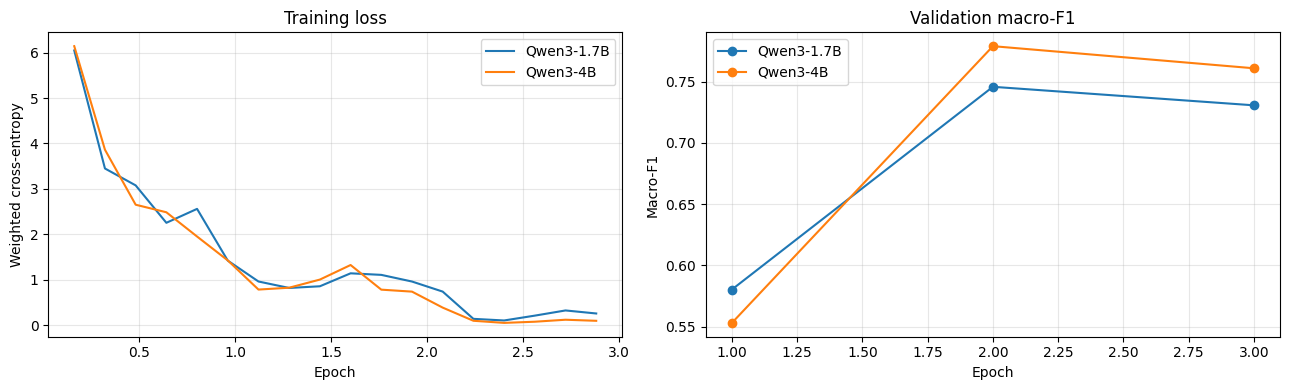

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for short_name, info in train_infos.items():
    history = pd.DataFrame(info["log_history"])
    train_loss = history.dropna(subset=["loss"]) if "loss" in history else pd.DataFrame()
    evals = history.dropna(subset=["eval_macro_f1"]) if "eval_macro_f1" in history else pd.DataFrame()
    if len(train_loss):
        axes[0].plot(train_loss["epoch"], train_loss["loss"], label=short_name)
    if len(evals):
        axes[1].plot(evals["epoch"], evals["eval_macro_f1"], marker="o", label=short_name)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Weighted cross-entropy")
axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 9.8 Comparison of all models

The table compares quality and costs of all models on the same 300 test articles:

- `macro_f1`, `accuracy`: quality on the test set
- `params`, `trainable_params`: size of the model and number of trained parameters
- `train_min`: training time in minutes (0 for zero-shot)
- `infer_s_per_100`: time to classify 100 articles in seconds
- `peak_gpu_gb`: maximum GPU memory during training (fine-tuning) or inference (zero-shot)

The times depend on the GPU (L4 or A100) and should be compared within one run.

,macro_f1,accuracy,train_min,infer_s_per_100,params,trainable_params,peak_gpu_gb
model,,,,,,,
TF-IDF + LogReg,0.535,0.873,0.15,0.077,-,-,0.00
Word2Vec + LogReg,0.547,0.793,0.11,0.270,-,-,0.00
Qwen3-1.7B zero-shot,0.479,0.873,0.00,11.070,1.72B,0,7.46
Qwen3-4B zero-shot,0.580,0.790,0.00,25.750,4.02B,0,12.98
Qwen3-1.7B QLoRA,0.629,0.913,38.00,10.660,1.74B,17442816,5.57
Qwen3-4B QLoRA,0.667,0.927,83.30,22.220,4.06B,33042944,8.40


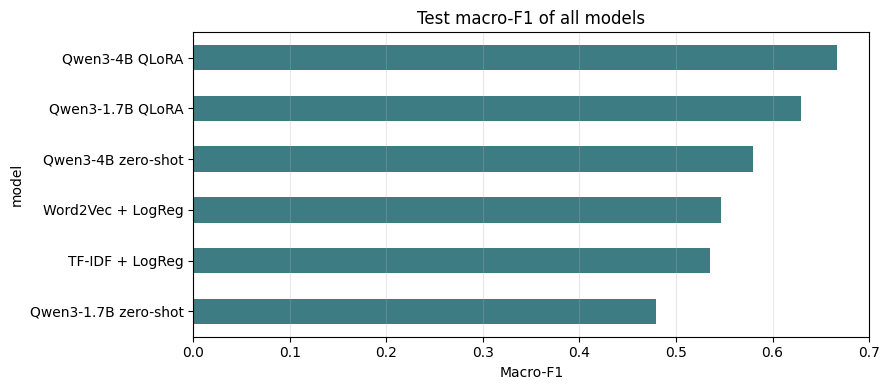

Best model: Qwen3-4B QLoRA
                             precision    recall  f1-score   support

          REGULATION_POLICY       0.74      0.81      0.77        21
            SECURITY_SAFETY       0.91      0.77      0.83        26
       BIAS_FAIRNESS_ETHICS       0.00      0.00      0.00         4
ACCOUNTABILITY_TRANSPARENCY       0.65      0.92      0.76        12
             NOT_GOVERNANCE       0.97      0.97      0.97       237

                   accuracy                           0.93       300
                  macro avg       0.65      0.69      0.67       300
               weighted avg       0.92      0.93      0.92       300



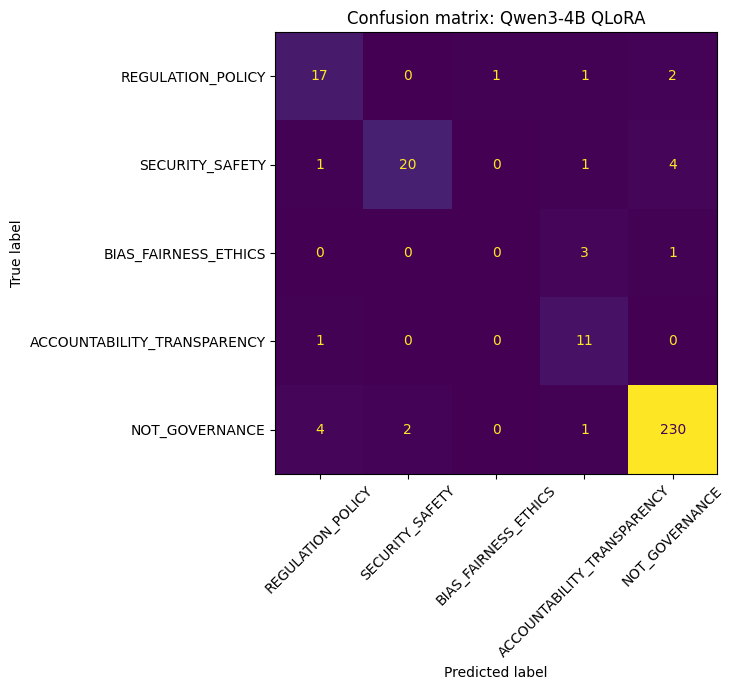

In [35]:
comparison = pd.DataFrame(results).set_index("model")
display(comparison)

fig, ax = plt.subplots(figsize=(9, 4))
comparison["macro_f1"].sort_values().plot.barh(ax=ax, color="#3D7C83")
ax.set(title="Test macro-F1 of all models", xlabel="Macro-F1")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

best_name = comparison["macro_f1"].idxmax()
print(f"Best model: {best_name}")
print(classification_report(test_l["label_id"], predictions[best_name], labels=range(len(LABELS)),
                            target_names=LABELS, zero_division=0))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(test_l["label_id"], predictions[best_name], labels=range(len(LABELS)),
                                        display_labels=LABELS, xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.show()

### 9.9 Embeddings of the fine-tuned model

Besides the extrinsic task, we compare the representations intrinsically, as in section 8: for the test articles we compute a document vector with Word2Vec (averaged word vectors) and with the fine-tuned model (average of the last hidden states over all tokens), and measure with the governance labels

- the silhouette score of the five classes (centered vectors, cosine distance),
- the macro-F1 of a logistic regression with 5-fold cross-validation on the vectors.

The fine-tuned model was trained on exactly these classes, so a better separation is expected; the comparison shows how strongly the fine-tuning reorganises the representation space compared with the unsupervised Word2Vec vectors. The t-SNE plots show the same comparison visually.

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[transformers] Qwen3ForSequenceClassification LOAD REPORT from: Qwen/Qwen3-1.7B
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning:

The least populated class in y has only 4 members, which is less than n_splits=5.

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning:

The least populated class in y has only 4 members, which is less than n_splits=5.



,representation,dimensions,silhouette,logreg_macro_f1_cv
0,Word2Vec,200,-0.065,0.458
1,Qwen3-1.7B fine-tuned,2048,0.045,0.697


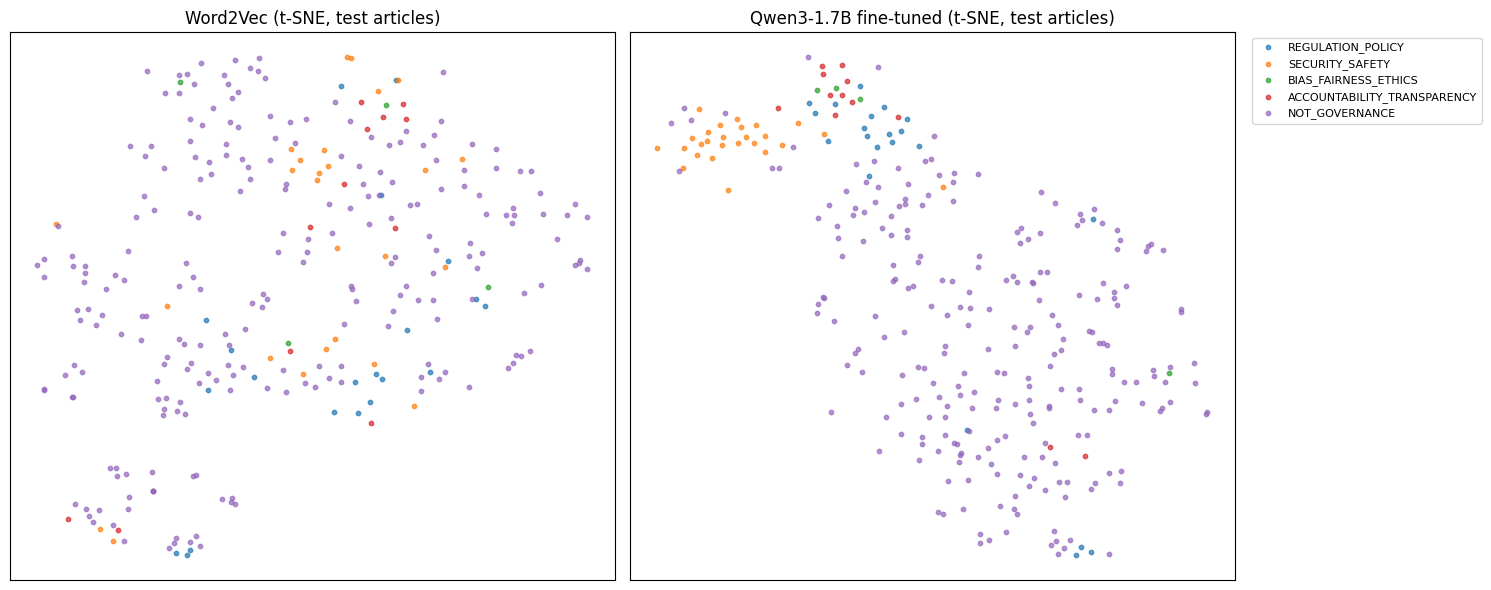

In [36]:
FT_MODEL = "Qwen3-1.7B"     # fine-tuned model for the embedding analysis and the trend analysis

tokenizer, classifier = load_classifier(MODELS[FT_MODEL])
classifier = PeftModel.from_pretrained(classifier, os.path.join(FT_DRIVE_FOLDER, f"adapter_{FT_MODEL}"))
_, llm_vectors = run_classifier(classifier, tokenizer, test_l["input_text"].tolist(), embeddings=True)
w2v_vectors = w2v_features(test_l)

rows, coords = [], {}
y_test = test_l["gold_label"].to_numpy()
for name, vectors in [("Word2Vec", w2v_vectors), (f"{FT_MODEL} fine-tuned", llm_vectors)]:
    centered = vectors - vectors.mean(axis=0)
    rows.append({
        "representation": name,
        "dimensions": vectors.shape[1],
        "silhouette": round(silhouette_score(centered, y_test, metric="cosine"), 3),
        "logreg_macro_f1_cv": round(cross_val_score(LogisticRegression(max_iter=3000, class_weight="balanced"),
                                                    centered, y_test, cv=5, scoring="f1_macro").mean(), 3),
    })
    coords[name] = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca",
                        random_state=RANDOM_STATE).fit_transform(centered)
display(pd.DataFrame(rows))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, xy) in zip(axes, coords.items()):
    for label in LABELS:
        mask = y_test == label
        ax.scatter(xy[mask, 0], xy[mask, 1], s=10, alpha=0.7, label=label)
    ax.set_title(f"{name} (t-SNE, test articles)")
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

### 9.10 Trend analysis of the governance subtopics

Finally we use the fine-tuned model to classify **all articles of the corpus** and analyse how the governance subtopics develop between September 2024 and August 2026. In contrast to the keyword filter of Stage 1, the model distinguishes the subtopics and excludes articles that only mention governance terms.

We use the smaller model (`FT_MODEL`), because it has to classify about 47,000 articles (about 30-45 minutes on an L4 GPU). If the larger model is clearly better in section 9.8, `FT_MODEL` can be changed. The predictions are stored in Drive in parts of 2,000 articles, so an interrupted run continues where it stopped. With `CORPUS_SAMPLE` a random sample can be classified first to test the cell.

In [37]:
CORPUS_SAMPLE = None      # e.g. 2000 for a quick test, None = all articles
CHUNK_SIZE = 2000
PRED_FILE = os.path.join(FT_DRIVE_FOLDER, f"corpus_predictions_{FT_MODEL}.csv")

corpus = df if CORPUS_SAMPLE is None else df.sample(n=CORPUS_SAMPLE, random_state=RANDOM_STATE)
corpus = corpus.assign(input_text=corpus.apply(model_input, axis=1))

done_urls = set(pd.read_csv(PRED_FILE)["url"]) if os.path.exists(PRED_FILE) else set()
todo = corpus[~corpus["url"].isin(done_urls)]
print(f"Already classified: {len(done_urls)}, to classify now: {len(todo)}")

for start in tqdm(range(0, len(todo), CHUNK_SIZE), desc="Corpus chunks"):
    chunk = todo.iloc[start:start + CHUNK_SIZE]
    probs = run_classifier(classifier, tokenizer, chunk["input_text"].tolist())
    out = pd.DataFrame({"url": chunk["url"].to_numpy(),
                        "pred_label": [ID2LABEL[i] for i in probs.argmax(1)],
                        "pred_prob": probs.max(1).round(3)})
    out.to_csv(PRED_FILE, mode="a", header=not os.path.exists(PRED_FILE), index=False)

corpus_pred = pd.read_csv(PRED_FILE).drop_duplicates("url").set_index("url")
corpus = corpus.join(corpus_pred, on="url")
del classifier
clear_gpu()

print(corpus["pred_label"].value_counts(normalize=True).round(3))
print(f"\nGovernance articles according to the model: {(corpus['pred_label'] != 'NOT_GOVERNANCE').mean():.1%}, "
      f"according to the Stage 1 keyword filter: {corpus['stage1_governance'].mean():.1%}")

Already classified: 0, to classify now: 47083


Corpus chunks:   0%|          | 0/24 [00:00<?, ?it/s]

pred_label
NOT_GOVERNANCE                 0.883
REGULATION_POLICY              0.046
SECURITY_SAFETY                0.041
ACCOUNTABILITY_TRANSPARENCY    0.027
BIAS_FAIRNESS_ETHICS           0.004
Name: proportion, dtype: float64

Governance articles according to the model: 11.7%, according to the Stage 1 keyword filter: 26.4%


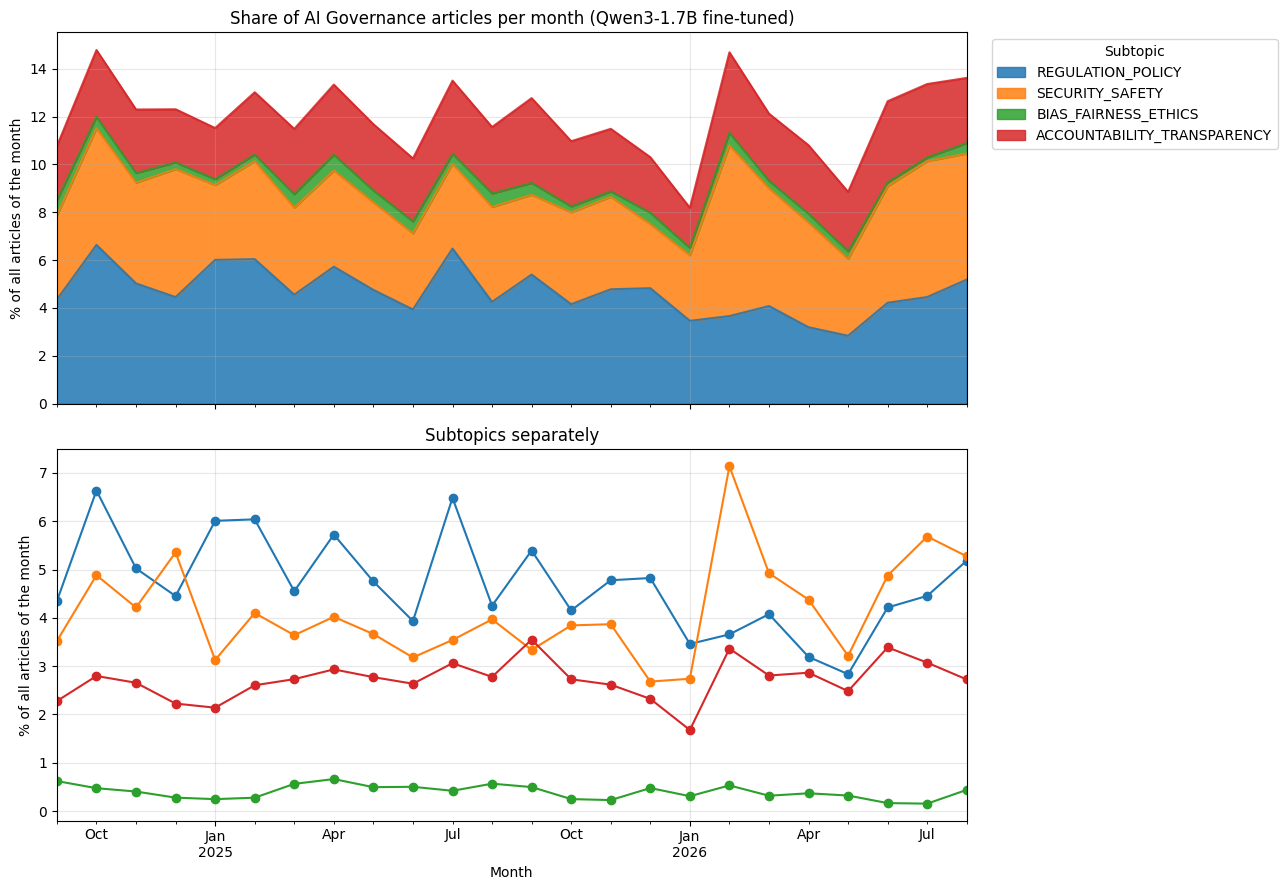

,overall_pct,first_6_months_pct,last_6_months_pct,change_pp,peak_month
pred_label,,,,,
REGULATION_POLICY,4.68,5.42,3.99,-1.42,2024-10
SECURITY_SAFETY,4.13,4.20,4.72,0.52,2026-02
BIAS_FAIRNESS_ETHICS,0.40,0.38,0.29,-0.09,2025-04
ACCOUNTABILITY_TRANSPARENCY,2.72,2.45,2.89,0.44,2025-09


In [38]:
GOV_LABELS = [label for label in LABELS if label != "NOT_GOVERNANCE"]

monthly_share = (
    pd.crosstab(corpus["month"], corpus["pred_label"], normalize="index")
    .reindex(columns=GOV_LABELS, fill_value=0) * 100
)
monthly_share.index = pd.to_datetime(monthly_share.index)

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
monthly_share.plot(kind="area", stacked=True, alpha=0.85, ax=axes[0])
axes[0].set(title=f"Share of AI Governance articles per month ({FT_MODEL} fine-tuned)",
            ylabel="% of all articles of the month")
axes[0].legend(title="Subtopic", bbox_to_anchor=(1.02, 1), loc="upper left")

monthly_share.plot(ax=axes[1], marker="o", linewidth=1.5)
axes[1].set(title="Subtopics separately", xlabel="Month", ylabel="% of all articles of the month")
axes[1].legend().remove()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

trend = pd.DataFrame({
    "overall_pct": monthly_share.mean(),
    "first_6_months_pct": monthly_share.iloc[:6].mean(),
    "last_6_months_pct": monthly_share.iloc[-6:].mean(),
})
trend["change_pp"] = trend["last_6_months_pct"] - trend["first_6_months_pct"]
trend["peak_month"] = monthly_share.idxmax().dt.strftime("%Y-%m")
display(trend.round(2))

### 9.11 Interpretation

**1. Labels and the Stage 1 keyword filter**

Phi-4 labelled 79% of the 2,600 selected articles as `NOT_GOVERNANCE`, although 60% of them had been selected by the Stage 1 keyword filter. Of the articles that passed the filter, **68% are not about AI governance** according to the labelling model; only 32% have a governance topic as their main subject. The keyword filter therefore mainly finds articles that *mention* security, policy or law, not articles that are *about* governance. Conversely, 5% of the articles outside the filter were labelled as governance articles, so the filter also misses some relevant articles.

The governance classes are very unequal: security (227) and regulation (217) are frequent, accountability/transparency (71) is rare, and bias/fairness/ethics (36) is very rare. The confidence of Phi-4 is close to 1.0 for almost all articles (median 1.00), so in 4-bit precision the model is overconfident and its confidence is of little use for selecting uncertain cases.

*[Update after re-running section 9.4: the team changed … of 300 label proposals. Agreement between Phi-4 and the final human labels: … %, Cohen's kappa: … .]*

**2. Classical representations vs. language models**

| Model | Macro-F1 | Accuracy |
|---|---|---|
| TF-IDF + LogReg | 0.535 | 0.873 |
| Word2Vec + LogReg | 0.547 | 0.793 |
| Qwen3-1.7B zero-shot | 0.479 | 0.873 |
| Qwen3-4B zero-shot | 0.580 | 0.790 |
| Qwen3-1.7B QLoRA | 0.629 | 0.913 |
| Qwen3-4B QLoRA | **0.667** | **0.927** |

Accuracy is misleading for this task: always predicting `NOT_GOVERNANCE` already gives an accuracy of 0.79 (237 of 300 test articles). Word2Vec and Qwen3-4B zero-shot are at this level, so we compare the models with the macro-F1 score.

- **Classical baselines** reach a macro-F1 of about 0.54. TF-IDF and Word2Vec are almost equal, i.e. averaged word vectors do not add much to a bag-of-words model for this task.
- **Without training**, the open models are not better than the classical baselines (1.7B: 0.479, 4B: 0.580). They know the topic, but do not follow the label definitions consistently.
- **Fine-tuning** improves the macro-F1 by +0.15 (1.7B) and +0.09 (4B) compared with zero-shot. The fine-tuned 1.7B model is clearly better than the 4B model without training.
- The **best model** (Qwen3-4B QLoRA) recognises almost all non-governance articles (230 of 237) and most security (20 of 26), regulation (17 of 21) and accountability articles (11 of 12). It fails completely on bias/fairness/ethics (F1 = 0): the 4 test articles of this class are predicted as accountability (3) or non-governance (1). With only 27 training examples, the class is too small, and its content overlaps strongly with accountability (both deal with responsible AI). Because the macro-F1 weights every class equally, a single class with F1 = 0 lowers the score by up to 0.2, although it contains only 4 test articles; the values for this class are therefore not reliable.

**3. Model size and costs**

| | Qwen3-1.7B QLoRA | Qwen3-4B QLoRA |
|---|---|---|
| Macro-F1 | 0.629 | 0.667 |
| Trainable parameters | 17.4 M (1.0%) | 33.0 M (0.8%) |
| Training time (L4) | 38 min | 83 min |
| Peak GPU memory | 5.6 GB | 8.4 GB |
| Inference per 100 articles | 10.7 s | 22.2 s |

The larger model is better by 0.04 macro-F1, but needs 2.2 times the training time and twice the inference time. Thanks to QLoRA, both models fit easily into the 24 GB of an L4 GPU (less memory than the 4B model needs for zero-shot inference in 16 bit: 13.0 GB). For classifying the whole corpus (47,000 articles), we therefore used the 1.7B model; for a small number of articles where quality matters most, the 4B model is the better choice.

The training curves show that both models reach their best validation score after **2 epochs** (1.7B: 0.75, 4B: 0.78). In the third epoch the training loss drops close to 0 while the validation score decreases slightly, which is a sign of beginning overfitting; the best epoch was kept automatically.

**4. Which representation captures the track best?**

- **Word2Vec** captures the *vocabulary* of the track well: the nearest neighbours are meaningful (`eu_ai_act` → `ai_act`, `transparency_obligations`, `gdpr`; `liability` → `tort`, `negligence`; `deepfake` → `impersonations`). On document level, however, averaged word vectors hardly separate governance articles: the silhouette score is close to 0 (section 8: 0.03; test set: −0.07), although a logistic regression can still find the information (section 8: macro-F1 0.77 for the Stage 1 label).
- The **fine-tuned language model** produces document representations in which the governance classes are clearly separated: silhouette 0.045 vs. −0.065 for Word2Vec, and a logistic regression on the vectors reaches a macro-F1 of 0.70 vs. 0.46. In the t-SNE plot the governance articles form a separate region, while they are spread over the whole plot for Word2Vec. This is expected, because the model was trained on these classes, but it shows that the fine-tuning reorganises the representation space according to the governance topics.

For **trend monitoring** in the selected track, the fine-tuned model is therefore the most effective representation: it can decide whether an article is *about* governance, which neither keywords nor averaged word vectors can do reliably. Word2Vec remains useful to explore the terminology of the track at very low cost, and TF-IDF is a strong and fast baseline.

**5. Trends of the governance subtopics (Sep 2024 - Aug 2026)**

According to the fine-tuned model, only **11.7%** of all articles are about AI governance, compared with 26.4% according to the Stage 1 keyword filter.

- **Regulation & policy** is the largest subtopic at the beginning, but loses relative weight (5.4% → 4.0% of all articles, −1.4 percentage points between the first and last six months). Its peaks in October 2024, January/February 2025 and July 2025 fall into the periods around the entry into force of the EU AI Act (August 2024) and its first application dates (prohibited practices in February 2025, obligations for general-purpose AI models in August 2025). This is a plausible explanation that should be verified by looking at the articles of these months.
- **Security & safety** increases slightly (4.2% → 4.7%) and is the largest subtopic in almost every month from February 2026, with a clear peak in **February 2026 (7.1%)** and a second increase from June 2026. This fits the Stage 1 result that AI agents became the fastest-growing topic: security risks of agents and their tool access (e.g. MCP) are a likely driver, which should also be checked with the articles of these months.
- **Accountability & transparency** is stable to slightly increasing (2.5% → 2.9%).
- **Bias, fairness & ethics** stays at a very low level (about 0.4% of all articles) throughout the period. This is consistent with the decline of the ethics topic in the Stage 1 topic model: in the media discourse, AI governance is discussed mainly as a question of regulation and security, and much less as a question of fairness.

**6. Limitations**

- The labels were created by one language model (Phi-4 in 4-bit) and are *silver labels*; errors of the labelling model are learned by the fine-tuned models.
- Only the title and the first 400 words of every article were used; topics that appear later in long articles are missed.
- Every article has exactly one label, although many articles cover several governance topics.
- The labelled sample was selected with the Stage 1 filter (60%) and does not have the class distribution of the whole corpus.
- The bias/fairness class is too small for a reliable evaluation; merging it with accountability or labelling more examples of this class would improve the analysis.
- The trend analysis uses the 1.7B model, which is slightly less accurate than the 4B model; small changes (below about 0.5 percentage points) should not be over-interpreted.

## 10. Comparative Evaluation (Contributor: TBD)

This chapter compares all representations and models of Stage 2 systematically, following the three requirements of the task:

| Requirement | Section | Question |
|---|---|---|
| Intrinsic evaluation: semantic similarity | 10.2 | Do the vector spaces reflect the meaning of words and governance terms? |
| Intrinsic evaluation: clustering quality and visualisation | 10.3 | Do articles of the same governance subtopic lie close together? |
| Extrinsic evaluation | 10.4 | How well do the representations solve the governance classification task, and how certain are the differences? |
| Trade-offs | 10.5 | What does each quality gain cost in model size, training time, inference time and GPU memory? |

**Compared representations.** We compare six representations of the same articles:

| Representation | Type | Dimensions | Trained on our data? |
|---|---|---|---|
| TF-IDF | sparse bag-of-words | 50,000 (300 after LSA for the geometric analyses) | vocabulary only |
| Word2Vec | averaged word vectors | 200 | yes, unsupervised (section 6) |
| Qwen3-1.7B frozen | mean of the last hidden states, no training | 2,048 | no |
| Qwen3-4B frozen | mean of the last hidden states, no training | 2,560 | no |
| Qwen3-1.7B fine-tuned | same, with the QLoRA adapter of section 9.7 | 2,048 | yes, supervised |
| Qwen3-4B fine-tuned | same, with the QLoRA adapter of section 9.7 | 2,560 | yes, supervised |

Comparing the *frozen* and the *fine-tuned* language models shows the effect of the fine-tuning on the same architecture; comparing the two sizes shows the effect of the model size.

**Data.** The analyses use the 2,600 labelled articles of chapter 9 (title and first 400 words). Classifiers are always trained on the training split and evaluated on the test split; the geometric analyses in 10.3 use the 600 validation and test articles, which were not used to train any model.

**Prerequisite and runtime.** Sections 9.1-9.8 must have been run in the same session (the chapter uses their models, labels and results). Computing the embeddings of the four language-model representations takes about 30-40 minutes on an L4 GPU; they are stored in Drive and loaded from there in later runs.

### 10.1 Setup and embeddings

For every language model we compute one vector per article: the average of the last hidden states over all tokens (*mean pooling*), as in section 9.9. For the word-level analyses in 10.2 we compute the same vector for single terms (e.g. "EU AI Act"), so that words can be compared in the language models in the same way as in Word2Vec.

In [ ]:
from gensim.test.utils import datapath
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, normalize

assert "predictions" in globals() and len(predictions), "Please run sections 9.1-9.8 first."

# Results of section 9.8
results_df = pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model")

# All labelled articles in a fixed order: train, validation, test
emb_docs = pd.concat([train_l, val_l, test_l])
DOC_TEXTS = emb_docs["input_text"].tolist()
DOC_SPLIT = emb_docs["split"].to_numpy()
DOC_Y = emb_docs["label_id"].to_numpy()
TRAIN, TEST = DOC_SPLIT == "train", DOC_SPLIT == "test"
y_test = DOC_Y[TEST]
NOT_GOV = LABEL2ID["NOT_GOVERNANCE"]

# --- Terms for the word-level analyses (section 10.2) ---------------------
# Triplets (anchor, related term, other term). "easy": the other term comes from general technology or
# business; "hard": the other term comes from a different governance subtopic.
TRIPLETS = [
    ("regulation", "legislation", "smartphone", "easy"),
    ("eu_ai_act", "gdpr", "kubernetes", "easy"),
    ("liability", "negligence", "bandwidth", "easy"),
    ("accountability", "oversight", "latency", "easy"),
    ("transparency", "explainability", "throughput", "easy"),
    ("bias", "discrimination", "dashboard", "easy"),
    ("fairness", "equality", "gpu", "easy"),
    ("deepfake", "impersonation", "spreadsheet", "easy"),
    ("cybersecurity", "ransomware", "recipe", "easy"),
    ("privacy", "surveillance", "chipset", "easy"),
    ("ftc", "antitrust", "smartwatch", "easy"),
    ("nist", "standards", "marketing", "easy"),
    ("compliance", "audit", "gaming", "easy"),
    ("safety", "risk", "revenue", "easy"),
    ("ethics", "morality", "kubernetes", "easy"),
    ("eu_ai_act", "regulation", "ransomware", "hard"),
    ("deepfake", "misinformation", "liability", "hard"),
    ("ransomware", "malware", "fairness", "hard"),
    ("discrimination", "bias", "audit", "hard"),
    ("explainability", "transparency", "ransomware", "hard"),
    ("liability", "lawsuit", "deepfake", "hard"),
    ("gdpr", "regulation", "phishing", "hard"),
    ("phishing", "cyberattack", "accountability", "hard"),
    ("audit", "accountability", "deepfake", "hard"),
    ("legislation", "lawmakers", "malware", "hard"),
    ("fairness", "bias", "phishing", "hard"),
    ("oversight", "accountability", "malware", "hard"),
    ("jailbreak", "prompt_injection", "legislation", "hard"),
    ("algorithmic_bias", "discrimination", "ransomware", "hard"),
    ("executive_order", "regulation", "deepfake", "hard"),
]
TERM_TEXT = {"eu_ai_act": "EU AI Act", "ai_act": "AI Act", "gdpr": "GDPR", "nist": "NIST", "ftc": "FTC"}


def term_text(token):
    """Natural spelling of a Word2Vec token for the language models."""
    return TERM_TEXT.get(token, token.replace("_", " "))


def load_word_pairs(name):
    """Standard word similarity benchmarks shipped with gensim: (word 1, word 2, human score)."""
    pairs = []
    with open(datapath(name), encoding="utf-8") as f:
        for line in f:
            if not line.startswith("#"):
                a, b, score = line.rstrip("\n").split("\t")[:3]
                pairs.append((a.lower(), b.lower(), float(score)))
    return pairs


BENCHMARKS = {"WordSim-353": load_word_pairs("wordsim353.tsv"), "SimLex-999": load_word_pairs("simlex999.txt")}
ALL_TERMS = sorted({t for trip in TRIPLETS for t in trip[:3]}
                   | {w for pairs in BENCHMARKS.values() for a, b, _ in pairs for w in (a, b)})
print(f"Articles: {len(emb_docs)} (train {TRAIN.sum()}, test {TEST.sum()}), terms: {len(ALL_TERMS)}")


# --- Embeddings of the language models (cached in Drive) ------------------
def llm_representation(name, hf_name, adapter_dir=None):
    path = os.path.join(FT_DRIVE_FOLDER, f"embeddings_{name.replace(' ', '_')}.npz")
    if USE_CACHE and os.path.exists(path):
        cached = np.load(path, allow_pickle=True)
        if list(cached["urls"]) == emb_docs["url"].tolist() and list(cached["terms"]) == ALL_TERMS:
            print(f"{name}: loaded from Drive.")
            return cached["docs"], dict(zip(ALL_TERMS, cached["term_vectors"])), float(cached["seconds_per_100"])
    tokenizer, encoder = load_classifier(hf_name)
    if adapter_dir:
        encoder = PeftModel.from_pretrained(encoder, adapter_dir)
    start = time.time()
    _, docs = run_classifier(encoder, tokenizer, DOC_TEXTS, embeddings=True)
    seconds_per_100 = (time.time() - start) / len(DOC_TEXTS) * 100
    _, terms = run_classifier(encoder, tokenizer, [term_text(t) for t in ALL_TERMS], embeddings=True)
    np.savez(path, docs=docs, term_vectors=terms, urls=np.array(emb_docs["url"]),
             terms=np.array(ALL_TERMS), seconds_per_100=seconds_per_100)
    del encoder
    clear_gpu()
    print(f"{name}: {docs.shape[1]} dimensions, {seconds_per_100:.1f} s per 100 articles.")
    return docs, dict(zip(ALL_TERMS, terms)), seconds_per_100


REPS = {
    "TF-IDF": {"docs": tfidf.transform(DOC_TEXTS), "terms": None, "seconds_per_100": None},
    "Word2Vec": {"docs": w2v_features(emb_docs),
                 "terms": {t: model.wv[t] for t in ALL_TERMS if t in model.wv.key_to_index},
                 "seconds_per_100": None},
}
for short_name, hf_name in MODELS.items():
    for variant, adapter in [("frozen", None), ("fine-tuned", os.path.join(FT_DRIVE_FOLDER, f"adapter_{short_name}"))]:
        docs, terms, speed = llm_representation(f"{short_name} {variant}", hf_name, adapter)
        REPS[f"{short_name} {variant}"] = {"docs": docs, "terms": terms, "seconds_per_100": speed}

print("\nRepresentations:", list(REPS))

### 10.2 Intrinsic evaluation I: semantic similarity of words and governance terms

We test whether the vector spaces reflect word meaning, on two levels:

1. **General word similarity.** Two standard benchmarks with human similarity ratings: **WordSim-353** (353 word pairs, measures *relatedness*, e.g. "cup - coffee") and **SimLex-999** (999 pairs, measures *similarity* in the strict sense, e.g. "cup - mug", and is known to be much harder). The score is the Spearman correlation between the cosine similarity of the vectors and the human ratings. To compare all representations on the same pairs, we only use pairs whose words are in the Word2Vec vocabulary.
2. **Governance terms.** 30 triplets (anchor, related term, other term) that we defined for our track, e.g. (*EU AI Act*, *GDPR*, *Kubernetes*). A triplet is solved if the anchor is more similar to the related term than to the other term. In the 15 **easy** triplets, the other term is a general technology or business word; in the 15 **hard** triplets, it comes from a different governance subtopic (e.g. *EU AI Act* - *regulation* vs. *ransomware*), so the representation must distinguish the subtopics of our track. The triplets were defined by the team from domain knowledge; some related terms also appear among the Word2Vec neighbours of section 7, so this test may slightly favour Word2Vec and should be read together with the independent benchmarks.

For Word2Vec we additionally report the standard **analogy test** of Mikolov et al. (e.g. *Paris : France = Berlin : ?*), which is only defined for static word vectors.

Before computing cosine similarities we subtract the mean vector of all terms of a representation. Language-model vectors all point in a similar direction (anisotropy); without centering, all similarities would be close to 1.

In [ ]:
def centered_terms(term_vectors):
    mean = np.mean(list(term_vectors.values()), axis=0)
    return {t: v - mean for t, v in term_vectors.items()}


def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


w2v_vocab = REPS["Word2Vec"]["terms"]
rows = []
for name, rep in REPS.items():
    if rep["terms"] is None:
        continue
    tv = centered_terms(rep["terms"])
    row = {"representation": name}
    for bench, pairs in BENCHMARKS.items():
        common = [(a, b, s) for a, b, s in pairs if a in w2v_vocab and b in w2v_vocab]
        sims = [cosine(tv[a], tv[b]) for a, b, _ in common]
        row[f"{bench} (Spearman)"] = round(spearmanr(sims, [s for *_, s in common]).correlation, 3)
    for kind in ["easy", "hard"]:
        hits = [cosine(tv[a], tv[p]) > cosine(tv[a], tv[n]) for a, p, n, k in TRIPLETS if k == kind]
        row[f"triplets {kind} (accuracy)"] = round(np.mean(hits), 3)
    rows.append(row)

similarity_table = pd.DataFrame(rows).set_index("representation")
print(f"Pairs used: WordSim-353 {sum(a in w2v_vocab and b in w2v_vocab for a, b, _ in BENCHMARKS['WordSim-353'])}, "
      f"SimLex-999 {sum(a in w2v_vocab and b in w2v_vocab for a, b, _ in BENCHMARKS['SimLex-999'])}; "
      f"triplets: 15 easy, 15 hard (random guessing: 0.5)")
display(similarity_table)

# Analogy test (Word2Vec only)
analogy_score, sections = model.wv.evaluate_word_analogies(datapath("questions-words.txt"), restrict_vocab=100000)
semantic = [s for s in sections if not s["section"].startswith("gram") and s["section"] != "Total accuracy"]
syntactic = [s for s in sections if s["section"].startswith("gram")]
share = lambda secs: sum(len(s["correct"]) for s in secs) / max(1, sum(len(s["correct"]) + len(s["incorrect"]) for s in secs))
print(f"\nWord2Vec analogies: total {analogy_score:.3f} (semantic {share(semantic):.3f}, syntactic {share(syntactic):.3f})")

# Triplets per representation: which ones are solved?
centered = {name: centered_terms(rep["terms"]) for name, rep in REPS.items() if rep["terms"] is not None}
detail = pd.DataFrame({
    name: [cosine(tv[a], tv[p]) > cosine(tv[a], tv[n]) for a, p, n, _ in TRIPLETS]
    for name, tv in centered.items()
}, index=[f"{term_text(a)} | {term_text(p)} vs. {term_text(n)} ({k})" for a, p, n, k in TRIPLETS])
print("\nTriplets not solved by the representation:")
display(detail[~detail.all(axis=1)].replace({True: "ok", False: "wrong"}))

**How to read the results.** Higher Spearman correlations mean that the similarities of the vectors agree better with human judgements. Word2Vec was trained on our 37 million tokens only, while the language models were pre-trained on trillions of tokens, so the language models are expected to win on general word similarity. On the governance triplets, Word2Vec has the advantage of having learned the vocabulary of exactly our corpus (e.g. `eu_ai_act`, `prompt_injection` as one token). The comparison of frozen and fine-tuned models shows whether the classification training changed the general meaning structure of the model: a decrease would indicate that fine-tuning specialises the representation for the task at the cost of general semantics.

### 10.3 Intrinsic evaluation II: clustering quality of the article representations

Here we evaluate the representations of whole articles on the 600 validation and test articles (none of them was used to train a model). Three measures, each answering a different question:

- **Silhouette score** (cosine, 5 classes): do the classes form compact, separated groups? (-1 to +1, 0 = strong overlap)
- **kNN precision@10:** for every article, which share of its 10 nearest neighbours has the same label? Averaged per class and then over the classes, so that the large class `NOT_GOVERNANCE` does not dominate. This is the measure that matters for *similarity search* (e.g. finding related articles for the RAG system in Stage 3).
- **Clustering of the governance articles:** k-means with k = number of governance subtopics, applied only to the governance articles, compared with the true subtopics by the **Adjusted Rand Index (ARI)** and **Normalized Mutual Information (NMI)** (0 = random, 1 = perfect). This tests whether the subtopics can be found *without* labels.

For the geometric analyses, TF-IDF is reduced to 300 dimensions with Latent Semantic Analysis (truncated SVD, fitted on the training articles), the usual way to compare sparse and dense representations.

Note: the labels of the validation articles are the Phi-4 silver labels, the labels of the test articles are the human-checked labels.

In [ ]:
EVAL = np.isin(DOC_SPLIT, ["val", "test"])
y_eval = DOC_Y[EVAL]
gov_eval = y_eval != NOT_GOV

X_tfidf_train = REPS["TF-IDF"]["docs"][TRAIN]
n_svd = min(300, X_tfidf_train.shape[1] - 1, X_tfidf_train.shape[0] - 1)
lsa = TruncatedSVD(n_components=n_svd, random_state=RANDOM_STATE).fit(X_tfidf_train)


def dense_docs(name):
    X = REPS[name]["docs"]
    return lsa.transform(X) if name == "TF-IDF" else np.asarray(X)


def document_metrics(X, y, gov):
    Xc = X - X.mean(axis=0)
    silhouette = silhouette_score(Xc, y, metric="cosine")
    neighbours = NearestNeighbors(n_neighbors=11, metric="cosine").fit(Xc)
    idx = neighbours.kneighbors(Xc, return_distance=False)[:, 1:]          # without the article itself
    same = (y[idx] == y[:, None]).mean(axis=1)
    knn_precision = pd.Series(same).groupby(y).mean().mean()                 # macro average over classes
    Xg, yg = normalize(Xc[gov]), y[gov]
    clusters = KMeans(n_clusters=len(np.unique(yg)), n_init=10, random_state=RANDOM_STATE).fit_predict(Xg)
    return {"silhouette": silhouette, "kNN precision@10": knn_precision,
            "ARI (governance)": adjusted_rand_score(yg, clusters),
            "NMI (governance)": normalized_mutual_info_score(yg, clusters)}


print(f"Evaluation articles: {EVAL.sum()}, of which governance articles: {gov_eval.sum()}")
clustering_table = pd.DataFrame(
    {name: document_metrics(dense_docs(name)[EVAL], y_eval, gov_eval) for name in REPS}
).T.round(3)
clustering_table.index.name = "representation"
display(clustering_table)

The t-SNE projections show the same comparison visually. Non-governance articles are drawn small and grey, so that the governance subtopics are visible.

In [ ]:
colors = {"REGULATION_POLICY": "#1f77b4", "SECURITY_SAFETY": "#ff7f0e", "BIAS_FAIRNESS_ETHICS": "#2ca02c",
          "ACCOUNTABILITY_TRANSPARENCY": "#d62728", "NOT_GOVERNANCE": "#c7c7c7"}
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, name in zip(axes.flatten(), REPS):
    X = dense_docs(name)[EVAL]
    xy = TSNE(n_components=2, perplexity=30, metric="cosine", init="pca",
              random_state=RANDOM_STATE).fit_transform(X - X.mean(axis=0))
    for label in ["NOT_GOVERNANCE"] + [l for l in LABELS if l != "NOT_GOVERNANCE"]:
        mask = y_eval == LABEL2ID[label]
        ax.scatter(xy[mask, 0], xy[mask, 1], s=6 if label == "NOT_GOVERNANCE" else 22,
                   c=colors[label], alpha=0.5 if label == "NOT_GOVERNANCE" else 0.9, label=label)
    row = clustering_table.loc[name]
    ax.set_title(f"{name}\nkNN precision@10 = {row['kNN precision@10']:.2f}, ARI = {row['ARI (governance)']:.2f}")
    ax.set_xticks([])
    ax.set_yticks([])
axes[0, 2].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.suptitle("t-SNE of the validation and test articles per representation", fontsize=15)
plt.tight_layout()
plt.show()

### 10.4 Extrinsic evaluation: governance classification

The extrinsic task is the classification of the governance subtopics from chapter 9 (300 human-checked test articles). We extend the comparison of section 9.8 in three ways:

1. **Linear probes on frozen representations.** A common alternative to fine-tuning is to use the hidden states of a frozen language model as features for a simple classifier. We train the same logistic regression on the embeddings of every language-model representation. If the probe on the *frozen* model already reaches the quality of the fine-tuned model, the expensive fine-tuning would not be necessary.
2. **Statistical uncertainty.** With only 300 test articles, and only a few articles in the small classes, differences of a few points can be random. We estimate **95% confidence intervals** for every model by bootstrapping the test set (1,000 resamples) and, for the best model, the share of resamples in which it beats each other model (*paired bootstrap*).
3. **Governance detection (binary).** Is an article about AI governance at all (any of the four subtopics) or not? This is exactly the decision the keyword filter of Stage 1 tried to make, so we can include the **Stage 1 keyword filter** as a baseline. With much larger classes, this measure is also more stable than the macro-F1 over five classes.

In [ ]:
# --- 1. Linear probes on the language-model embeddings ---------------------
probe_predictions = {}
for name, rep in REPS.items():
    if name in ("TF-IDF", "Word2Vec"):            # identical to the baselines of section 9.5
        continue
    probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=0.1, class_weight="balanced"))
    probe.fit(rep["docs"][TRAIN], DOC_Y[TRAIN])
    probe_predictions[f"Probe: {name}"] = probe.predict(rep["docs"][TEST])

all_predictions = {**{name: np.asarray(p) for name, p in predictions.items()}, **probe_predictions}

# --- 2. Scores with bootstrap confidence intervals -------------------------
N_BOOT = 1000
rng = np.random.default_rng(RANDOM_STATE)
boot_idx = rng.integers(0, len(y_test), size=(N_BOOT, len(y_test)))
is_gov = y_test != NOT_GOV


def macro_f1(y, p):
    return f1_score(y, p, average="macro", labels=range(len(LABELS)), zero_division=0)


def binary_f1(y, p):
    return f1_score(y != NOT_GOV, p != NOT_GOV, zero_division=0)


boot_macro = {name: np.array([macro_f1(y_test[i], p[i]) for i in boot_idx]) for name, p in all_predictions.items()}

rows = []
for name, p in all_predictions.items():
    lo, hi = np.percentile(boot_macro[name], [2.5, 97.5])
    boot_bin = [binary_f1(y_test[i], p[i]) for i in boot_idx]
    rows.append({"model": name, "macro_f1": macro_f1(y_test, p), "macro_f1_ci_low": lo, "macro_f1_ci_high": hi,
                 "governance_f1": binary_f1(y_test, p),
                 "governance_f1_ci": f"[{np.percentile(boot_bin, 2.5):.2f}, {np.percentile(boot_bin, 97.5):.2f}]",
                 "accuracy": accuracy_score(y_test, p)})

# Stage 1 keyword filter: governance detection only
keyword_pred = test_l["stage1_governance"].to_numpy()
keyword_f1 = f1_score(is_gov, keyword_pred, zero_division=0)
boot_kw = [f1_score(is_gov[i], keyword_pred[i], zero_division=0) for i in boot_idx]
rows.append({"model": "Stage 1 keyword filter", "macro_f1": np.nan, "macro_f1_ci_low": np.nan, "macro_f1_ci_high": np.nan,
             "governance_f1": keyword_f1,
             "governance_f1_ci": f"[{np.percentile(boot_kw, 2.5):.2f}, {np.percentile(boot_kw, 97.5):.2f}]",
             "accuracy": accuracy_score(is_gov, keyword_pred)})

extrinsic_table = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)
display(extrinsic_table.round(3))

# Paired bootstrap: how often does the best model beat each other model?
best = extrinsic_table["macro_f1"].idxmax()
paired = pd.Series({name: (boot_macro[best] > boot_macro[name]).mean()
                    for name in boot_macro if name != best}).sort_values()
print(f"Best model: {best}. Share of bootstrap samples in which it has the higher macro-F1:")
display(paired.round(3).to_frame("P(best > model)"))

In [ ]:
# Macro-F1 with confidence intervals
plot_df = extrinsic_table.dropna(subset=["macro_f1"]).sort_values("macro_f1")
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.2]})
err = [plot_df["macro_f1"] - plot_df["macro_f1_ci_low"], plot_df["macro_f1_ci_high"] - plot_df["macro_f1"]]
bar_colors = ["#3D7C83" if "QLoRA" in n else "#9ecae1" if n.startswith("Probe") else "#bdbdbd" for n in plot_df.index]
axes[0].barh(plot_df.index, plot_df["macro_f1"], xerr=err, color=bar_colors, capsize=3)
axes[0].set(title="Test macro-F1 with 95% bootstrap confidence intervals", xlabel="Macro-F1")
axes[0].grid(axis="x", alpha=0.3)

# F1 per class and model
per_class = pd.DataFrame({
    name: f1_score(y_test, all_predictions[name], average=None, labels=range(len(LABELS)), zero_division=0)
    for name in plot_df.index[::-1]
}, index=LABELS).T
im = axes[1].imshow(per_class.values, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
axes[1].set_xticks(range(len(LABELS)))
axes[1].set_xticklabels([l.replace("_", "\n", 1) for l in LABELS], fontsize=8)
axes[1].set_yticks(range(len(per_class)))
axes[1].set_yticklabels(per_class.index)
for i in range(per_class.shape[0]):
    for j in range(per_class.shape[1]):
        axes[1].text(j, i, f"{per_class.iat[i, j]:.2f}", ha="center", va="center", fontsize=8)
axes[1].set_title(f"F1 per class (test support: {', '.join(str((y_test == k).sum()) for k in range(len(LABELS)))})")
plt.colorbar(im, ax=axes[1], fraction=0.03)
plt.tight_layout()
plt.show()

**How to read the results.** Overlapping confidence intervals mean that the test set is too small to prove a difference between two models; a value of `P(best > model)` above 0.95 corresponds roughly to a significant difference at the 5% level. The per-class table shows which subtopics are responsible for the differences; classes with very few test articles (see support) have very uncertain F1 values. The comparison of *Probe: ... frozen*, *Probe: ... fine-tuned* and *... QLoRA* separates the contribution of the pre-trained representation from the contribution of the fine-tuning.

### 10.5 Trade-offs: quality, size, speed and GPU memory

The table combines the quality of every model with its costs. All times were measured in this notebook on the same GPU (language models) or on the Colab CPU (TF-IDF, Word2Vec). `hours_full_corpus` extrapolates the inference time to all ~47,000 articles of the corpus, which is the relevant cost for trend monitoring. For the probes, the inference cost is the time to compute the embeddings (the logistic regression itself takes milliseconds); their training cost is one embedding pass over the 2,000 training articles plus a few seconds for the logistic regression.

In [ ]:
cost = results_df[["params", "trainable_params", "train_min", "infer_s_per_100", "peak_gpu_gb"]].copy()
for name in probe_predictions:
    rep = REPS[name.replace("Probe: ", "")]
    speed, dims = rep["seconds_per_100"], rep["docs"].shape[1]
    cost.loc[name] = pd.Series({
        "params": cost.loc[f"{name.split()[1]} zero-shot", "params"],
        "trainable_params": len(LABELS) * (dims + 1),                    # weights of the logistic regression
        "train_min": round(speed * TRAIN.sum() / 100 / 60, 1),          # one embedding pass over the training set
        "infer_s_per_100": round(speed, 2), "peak_gpu_gb": np.nan,
    })
cost["hours_full_corpus"] = (cost["infer_s_per_100"] * len(df) / 100 / 3600).round(2)
tradeoffs = extrinsic_table[["macro_f1", "macro_f1_ci_low", "macro_f1_ci_high", "governance_f1"]].join(cost, how="inner")
tradeoffs = tradeoffs.sort_values("macro_f1", ascending=False)
display(tradeoffs.round(3))

fig, ax = plt.subplots(figsize=(11, 6.5))
for name, row in tradeoffs.iterrows():
    x = max(row["infer_s_per_100"], 0.01)
    color = "#3D7C83" if "QLoRA" in name else "#9ecae1" if name.startswith("Probe") else "#D95D4F" if "zero-shot" in name else "#7f7f7f"
    size = 60 + 40 * (row["peak_gpu_gb"] if pd.notna(row["peak_gpu_gb"]) else 0)
    ax.errorbar(x, row["macro_f1"], yerr=[[row["macro_f1"] - row["macro_f1_ci_low"]], [row["macro_f1_ci_high"] - row["macro_f1"]]],
                fmt="none", ecolor=color, alpha=0.4)
    ax.scatter(x, row["macro_f1"], s=size, color=color, alpha=0.85, edgecolor="black", linewidth=0.5)
    ax.annotate(name, (x, row["macro_f1"]), textcoords="offset points", xytext=(7, 4), fontsize=8)
ax.set_xscale("log")
ax.set(xlabel="Inference time per 100 articles in seconds (log scale)", ylabel="Test macro-F1",
       title="Quality vs. inference cost (marker size = peak GPU memory)")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

### 10.6 Summary: which representation captures the governance track best? (to be completed after the run)

The summary should answer the following questions with the values of sections 10.2-10.5. The structure below is a suggestion; every statement should refer to a number of the tables above.

1. **Word level (10.2):** Which representation agrees best with human similarity judgements (WordSim-353, SimLex-999)? Which one distinguishes governance terms best, in particular in the hard triplets? Did the fine-tuning change the general semantic quality of the language models?
2. **Article level (10.3):** Which representation places articles of the same subtopic next to each other (kNN precision) and allows to find the subtopics without labels (ARI/NMI)? What do the t-SNE plots show?
3. **Task level (10.4):** How large are the differences between the models, and which ones are statistically robust (confidence intervals, paired bootstrap)? How much do frozen embeddings with a linear probe achieve compared with QLoRA? How much better than the Stage 1 keyword filter is the best model in detecting governance articles?
4. **Costs (10.5):** Which model offers the best quality per cost? Is the larger model worth its additional training time, inference time and memory?
5. **Recommendation:** Which representation should be used for which purpose in the project, e.g. (a) exploring the vocabulary of the track, (b) classifying and monitoring governance articles over time, and (c) retrieving similar articles for the RAG system in Stage 3?